# __Group Assignment - Predicting Airbnb Listing Prices in Brisbane, Australia__

---

**Kaggle Competition Deadline:** Friday, 5 June 2026 at 3:00 PM (Week 13)  
**Assignment Due Date (iLearn):** Friday, 5 June 2026 at 11:59 PM (Week 13)  
**Total Marks:** 30  

**Overview**  
In this group assignment, you will form a team of three students and participate in a forecasting competition on Kaggle.

---
### General Instructions

- Each team member must create a Kaggle account and join the competition using the link:  
  https://www.kaggle.com/t/554f205a43a94920943d5227ae9dcbdb  

- Form a team of three students:  
  Choose a team leader who will create the team and invite the other members  
  The team name must begin with the unit code  

- All team members are expected to contribute to all tasks.  
  Each member must take primary responsibility for one of the three tasks.

- Your predictions must be generated using models developed in this assignment.  
  **A mark of zero will be awarded if your submitted forecasts cannot be reproduced from your code.**

- All results must be clearly presented and directly verifiable from your outputs and explanations.

- All written answers must be written in clear and complete sentences, supported by relevant tables, summary statistics, and visualisations where appropriate.  


<hr style="width:20%;margin-left:0;"> 

### Marks

- **Total Marks:** 30 (across 3 tasks)
    
- **Individual Mark Allocation:**  
  Each student’s mark is calculated as:  
      **50% × overall group assignment mark**  
      **50% × mark for the task they are responsible for**

<hr style="width:20%;margin-left:0;"> 

### Assignment Submission

1. **Kaggle Submission:**  
   - Submit your team’s forecasts on Kaggle to be ranked on the leaderboard  
2. **iLearn Submission (team leader only):**  
   - Submit the assignment as a Jupyter notebook, renamed to your **Kaggle team name**  
   - The notebook must include:
     - Names and student ID numbers of all team members  
     - Your Kaggle team name  
   - Submit **one 15-minute video presentation** of your work  
     - A penalty of **5 marks will be deducted per task** if a video presentation is not provided  

---
---

### <span style="background-color: yellow;">Fill out the following information

- Team Name on Kaggle: BUSA8001_HTQ
- Team Leader and Team Member 1: Thi Huyen Nguyen
- Team Member 2: Pham Khanh Quynh Nguyen
- Team Member 3: Nhat Thanh Thuy Do

---
---

## Task 1: Problem Description and Exploratory Data Analysis (EDA)  

**Total Marks: 10**

- Based on the Competition Overview, datasets, and additional information provided on Kaggle, along with insights gained from your own research (including relevant academic sources such as Google Scholar), answer the following questions.  
- Do not discuss any predictive models in this task.


---

Student in charge of this task: Pham Khanh Quynh Nguyen


<hr style="width:25%;margin-left:0;">    

#### 1. Forecasting Problem (2 marks)  
In approximately **300 words**, explain what we are trying to predict and how this problem can be applied in a real-world context.  
Discuss who may benefit from these predictions and how they might use them.


**Answer:**

The objective of this competition is to predict the nightly listing price (AUD) of Airbnb properties in Brisbane, Australia. Using information about each property, host, location, availability, and guest reviews, participants are required to estimate prices for listings in the test dataset. The training dataset contains 3,735 observations with known prices, while the test dataset contains 1,601 unseen listings. Since the target variable is a continuous numerical value, this represents a supervised regression problem within predictive analytics.

From a business perspective, Airbnb pricing is influenced by multiple factors, including property characteristics, accommodation capacity, location, amenities, host reputation, and market demand. This aligns with the concept of hedonic pricing, where the value of a product or service is determined by its underlying attributes. In the short-term rental market, hosts are responsible for setting their own prices and must balance profitability with competitiveness. Consequently, accurately estimating market prices has become an important challenge in the sharing economy and hospitality industries.

The practical significance of this problem is evident in Brisbane’s growing short-term rental market, where thousands of Airbnb listings compete for guests. Even small pricing errors can lead to revenue losses through underpricing or reduced bookings due to overpricing. Therefore, accurate price forecasting can support more effective and data-driven pricing decisions.

Several stakeholder groups can benefit from these predictions:
* **Hosts and Property Investors:** Use predicted prices as benchmarks to optimise pricing strategies and maximise revenue.
* **Property Management Companies:** Apply pricing insights across multiple properties to improve portfolio performance and operational efficiency.
* **Travellers and Guests:** Benefit from more transparent and competitive pricing, helping them identify better-value accommodation options.
* **Airbnb and Other Rental Platforms:** Use pricing insights to improve recommendation systems, pricing tools, and marketplace efficiency.
* **Policymakers and Urban Planners:** Monitor market trends and assess the economic impacts of short-term rentals on tourism and housing affordability.

Overall, Airbnb price prediction transforms a complex pricing problem into a practical analytical task that supports evidence-based decision-making for businesses, consumers, and policymakers.

<hr style="width:25%;margin-left:0;">   

#### 2. Evaluation Criteria (2 marks)  
Describe the evaluation metric used in this competition to assess forecasting performance.  
Provide the equation and discuss its advantages and potential limitations.

**Metric: Mean Absolute Percentage Error (MAPE)**

The evaluation metric used in this competition is the Mean Absolute Percentage Error (MAPE). MAPE measures the average percentage difference between actual and predicted values, providing an intuitive assessment of forecasting accuracy. A lower MAPE indicates better predictive performance because predictions are closer to the actual values.

The formula is:
$$
\text{MAPE} = \frac{1}{n} \sum_{i=1}^{n} \left| \frac{A_i - F_i}{A_i} \right| \times 100
$$

Where:
* n = number of observations
* $A_i$ = actual price for listing $i$
* $F_i$ = forecasted (predicted) price for listing $i$
* The vertical bars denote absolute value

MAPE offers several advantages for this competition. First, it is scale-independent, meaning errors are expressed as percentages rather than dollar values. This allows meaningful comparisons across Airbnb listings with very different price levels. For example, a 50 AUD error on a 100 AUD listing is more significant than the same error on a 500 AUD listing, and MAPE captures this distinction naturally. Second, MAPE is highly interpretable, as stakeholders can easily understand the average percentage deviation between predicted and actual prices. Third, because it is unit-free, MAPE enables fair comparison between different forecasting models.

However, MAPE also has limitations. It applies an asymmetric penalty, meaning large overpredictions can generate disproportionately large errors and potentially bias model evaluation. In addition, MAPE is sensitive to observations with relatively low prices, where small absolute prediction errors can translate into large percentage errors. Finally, MAPE becomes undefined when actual values equal zero due to division by zero. Although this is unlikely in the Airbnb dataset because listing prices are positive, very low-priced listings may still produce unstable percentage errors.

Overall, MAPE is an appropriate evaluation metric for Airbnb price forecasting because it provides an intuitive and business-relevant measure of prediction accuracy while allowing consistent comparison across listings with different price ranges.

<hr style="width:25%;margin-left:0;">      

#### 3. Missing Values (2 marks)  
Identify and report the number of missing values in the dataset using appropriate summaries.  
Clearly interpret your findings for both the training and test datasets.

In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

In [2]:
# import data
train = pd.read_csv("asba-predictive-analytics-competition-s-1-2026/train.csv")
test = pd.read_csv("asba-predictive-analytics-competition-s-1-2026/test.csv")

print(f"train_shape: {train.shape}")
print(f"test_shape: {test.shape}")

print(train.info())

train.head(3)

train_shape: (3735, 65)
test_shape: (1601, 64)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3735 entries, 0 to 3734
Data columns (total 65 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   ID                                            3735 non-null   int64  
 1   source                                        3735 non-null   object 
 2   name                                          3735 non-null   object 
 3   description                                   3697 non-null   object 
 4   neighborhood_overview                         1754 non-null   object 
 5   host_id                                       3735 non-null   int64  
 6   host_name                                     3733 non-null   object 
 7   host_since                                    3733 non-null   object 
 8   host_location                                 2917 non-null   object 
 9   host_about      

,ID,source,name,description,neighborhood_overview,host_id,host_name,host_since,host_location,host_about,...,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price
0,0,city scrape,The Nestt,Enjoy a memorable visit when you stay in this ...,NaN,38029254,Mark,2015-07-09,NaN,NaN,...,4.61,4.28,4.50,f,8,8,0,0,0.58,$97.00
1,1,city scrape,Bayside Bliss - By the Water & Near the Airport,"Relax by the water and close to the airport, B...",Wynnum is nestled along Brisbane's sunny south...,33488214,Claire,2015-05-16,"Wynnum, Australia",NaN,...,4.94,4.88,4.69,f,1,1,0,0,0.93,$205.00
2,2,city scrape,Cozy 1 Bedroom Apartment with Infinity Pool,My stunning apartment is located in one of the...,Staying here allows you to experience the neve...,401146490,Hao,2021-05-11,NaN,"Roger and I love traveling, we fell in love wi...",...,4.81,4.67,4.56,t,7,7,0,0,1.33,$186.00


In [3]:
def missing_summary(df, dataset_name):
    summary = pd.DataFrame({
        "missing_count": df.isnull().sum(),
        "missing_percentage": (df.isnull().sum() / len(df) * 100).round(2)
    })

    summary = summary[summary["missing_count"] > 0]
    summary = summary.sort_values("missing_count", ascending=False)

    print(f"\nMissing Values Summary: {dataset_name}")
    print(f"Dataset shape: {df.shape}")
    print(f"Total missing values: {df.isnull().sum().sum()}")
    
    return summary

train_missing = missing_summary(train, "Training Dataset")
test_missing = missing_summary(test, "Test Dataset")

display(train_missing)
display(test_missing)


Missing Values Summary: Training Dataset
Dataset shape: (3735, 65)
Total missing values: 13302

Missing Values Summary: Test Dataset
Dataset shape: (1601, 64)
Total missing values: 5582


,missing_count,missing_percentage
host_neighbourhood,3599,96.36
neighborhood_overview,1981,53.04
host_about,1492,39.95
host_location,818,21.90
reviews_per_month,437,11.70
review_scores_rating,437,11.70
review_scores_accuracy,437,11.70
review_scores_cleanliness,437,11.70
review_scores_checkin,437,11.70
review_scores_communication,437,11.70


,missing_count,missing_percentage
host_neighbourhood,1536,95.94
neighborhood_overview,847,52.90
host_about,618,38.60
host_location,337,21.05
reviews_per_month,183,11.43
review_scores_communication,183,11.43
last_review,183,11.43
first_review,183,11.43
review_scores_cleanliness,183,11.43
review_scores_checkin,183,11.43


### Missing Values Summary and Interpretation

A missing value analysis was conducted on both the training and test datasets to assess data completeness and identify potential data quality issues. The training dataset contains 3,735 observations and 65 variables, with a total of **13,302 missing values**, while the test dataset contains 1,601 observations and 64 variables, with **5,582 missing values**. Overall, both datasets exhibit very similar missing value patterns, suggesting that the missingness is systematic and consistent across the two samples.

The largest proportion of missing values occurs in host and neighbourhood description variables. In the training dataset, **host_neighbourhood** has the highest missing rate (96.36%), followed by **neighborhood_overview** (53.04%), **host_about** (39.95%), and **host_location** (21.90%). Similar percentages are observed in the test dataset. These variables primarily contain optional descriptive information provided by hosts, indicating that the missing values are more likely due to incomplete profile information rather than data collection errors.

A second group of variables with notable missingness relates to reviews. Variables such as **first_review**, **last_review**, **reviews_per_month**, and multiple review score measures contain approximately 11–12% missing values in both datasets. This pattern is likely associated with listings that have not yet received guest reviews, meaning the missing values may carry meaningful information about listing activity and popularity.

In contrast, most property-related attributes, including **bedrooms**, **beds**, **bathrooms**, and minimum/maximum night restrictions, contain very few missing values, generally below 1%. This indicates that the core characteristics of Airbnb listings are largely complete and reliable.

Overall, the missing value patterns are consistent between the training and test datasets and appear concentrated in optional host descriptions and review-related variables. While the extent of missingness varies across features, the missing values are manageable and should be addressed during the data preparation stage before predictive modelling is undertaken.


<hr style="width:25%;margin-left:0;">      

#### 4. Univariate Data Analysis (2 marks)  
Present and discuss key *univariate* characteristics of the training data.  
Use appropriate summary statistics and visualisations (e.g. histograms for numerical variables, bar charts for categorical variables) to support your analysis.  
For example you may consider variables such as price, room type, number of listings per host, availability, or geographical location.

In [4]:
# Clean Price: Create price_numeric column
train['price_numeric'] = (
    train['price']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
)
train['price_numeric'] = pd.to_numeric(train['price_numeric'], errors='coerce')

print("Original price column (first 5):")
print(train['price'].head())

print("\nCleaned price_numeric column (first 5):")
print(train['price_numeric'].head())

print(f"\nData type : {train['price_numeric'].dtype}")
print(f"Missing values: {train['price_numeric'].isnull().sum()}")

Original price column (first 5):
0     $97.00
1    $205.00
2    $186.00
3    $157.00
4    $300.00
Name: price, dtype: object

Cleaned price_numeric column (first 5):
0     97.0
1    205.0
2    186.0
3    157.0
4    300.0
Name: price_numeric, dtype: float64

Data type : float64
Missing values: 0


In [5]:
# Summary Statistics
numerical_cols = [
    'price_numeric', 'accommodates', 'bathrooms', 'bedrooms', 'beds',
    'minimum_nights', 'availability_30', 'number_of_reviews',
    'review_scores_rating', 'reviews_per_month',
    'host_response_rate', 'host_acceptance_rate'
]
display(train[numerical_cols].describe().round(2))

,price_numeric,accommodates,bathrooms,bedrooms,beds,minimum_nights,availability_30,number_of_reviews,review_scores_rating,reviews_per_month
count,3735.00,3735.00,3730.00,3733.00,3732.00,3735.0,3735.00,3735.00,3298.00,3298.00
mean,230.08,3.70,1.42,1.76,2.12,4.0,12.07,50.60,4.74,2.08
std,194.65,2.31,0.71,1.11,1.58,15.3,9.03,90.08,0.37,1.81
min,36.00,1.00,0.00,0.00,0.00,1.0,0.00,0.00,1.00,0.01
25%,129.00,2.00,1.00,1.00,1.00,1.0,4.00,4.00,4.67,0.77
50%,193.00,3.00,1.00,1.00,2.00,2.0,11.00,18.00,4.83,1.64
75%,267.00,4.00,2.00,2.00,3.00,3.0,19.00,56.00,4.95,2.95
max,5000.00,16.00,9.00,9.00,24.00,500.0,30.00,1130.00,5.00,13.62


## Summary Statistics — Key Numerical Variables (Training Dataset, n = 3,735)

The table below presents descriptive statistics for the key numerical 
variables selected for this analysis. Note that `review_scores_rating` 
and `reviews_per_month` are computed on 3,298 observations, as 437 
listings (11.7%) have not yet received any reviews — consistent with 
the missing values findings in Q3.

### 1. Price Distribution

The nightly price (`price_numeric`) is **strongly right-skewed** 
(skewness = 7.48), with a mean of **230 AUD** and a median of 
**193 AUD**. The notable gap between mean and median confirms the 
presence of high-value outliers — the most expensive listing reaches 
**5,000 AUD per night**, while the cheapest is 36 AUD. The 
interquartile range spans **129 AUD (25th percentile) to 267 AUD 
(75th percentile)**, indicating that the central 50% of Brisbane 
listings fall within a relatively narrow 138 AUD band. The 
log-transformed price distribution (skewness = 0.25) is approximately 
normal, justifying the use of log transformation as the target 
variable during model training to stabilise variance and improve 
prediction accuracy.

### 2. Property Size Variables

**Accommodates** ranges from 1 to 16 guests with a median of 3, 
confirming that most Brisbane listings are small to medium-sized 
properties suited for couples or small groups. The mean (3.70) 
slightly exceeds the median, indicating a mild right skew with 
some large-capacity listings pulling the average up.

**Bedrooms** has a median of 1 bedroom and a mean of 1.76, with 
values ranging from 0 (studio apartments) to 9. The distribution 
is right-skewed — the majority of listings are 1–2 bedroom 
properties, with larger configurations becoming progressively rarer.

**Beds** has a median of 2 and a mean of 2.12, with a maximum of 24. 
The higher maximum relative to bedrooms reflects listings with 
multiple beds per room — such as bunk beds or sofa beds — common 
in budget and shared accommodation setups.

**Bathrooms** has a median of 1.0 and a mean of 1.42, ranging from 
0 to 9. The majority of listings provide 1 bathroom, consistent with 
the dominance of single-bedroom apartments in the Brisbane STR market. 
The small number of listings reporting 0 bathrooms likely reflects 
data entry issues or shared facilities.

### 3. Room Type Distribution

The Brisbane Airbnb market is heavily dominated by **Entire home/apt** 
listings, accounting for **2,854 listings (76.4%)** of all training 
records. **Private rooms** represent the second largest category at 
**875 listings (23.4%)**. Shared rooms (0.1%) and Hotel rooms (0.1%) 
are negligible, together comprising fewer than 10 listings. This 
distribution confirms that the vast majority of Brisbane STR guests 
seek exclusive property access rather than shared accommodation, and 
underlines the importance of `room_type` as a key pricing predictor.

### 4. Host Response Time Distribution

**77.1% (2,879)** of hosts respond **within an hour**, making this 
the dominant response category by a large margin. Only **8.6%** 
respond within a few hours, **4.8%** within a day, and **1.8%** 
take a few days or more. The remaining 7.7% have no recorded response 
time, corresponding to hosts without any prior booking enquiries. 
This strong concentration in the fastest response category reflects 
the competitive nature of the Brisbane STR market, where responsiveness 
is critical for securing bookings and maintaining platform visibility.

### 5. Availability Over Next 30 Days

`availability_30` shows a median of just **11 days** and a mean of 
**12 days** out of a maximum of 30, confirming that a large proportion 
of Brisbane listings are heavily booked or deliberately blocked in the 
near term. The strong spike at 0 days available — approximately 480 
listings — indicates a significant segment of fully booked or 
host-blocked listings. The relatively even distribution from 5–28 
days with a modest spike at 30 days (fully available listings) 
suggests a mix of high-demand listings and casually managed 
properties that remain open throughout the month.

### 6. Review Variables

**Review Scores Rating** is **strongly left-skewed** with a median 
of **4.83 out of 5.0** and a standard deviation of only 0.37. The 
distribution is heavily concentrated between 4.5 and 5.0, creating 
a pronounced ceiling effect. The tight interquartile range 
(4.67–4.95) confirms that nearly all active Brisbane listings 
maintain consistently high guest satisfaction, which limits this 
variable's discriminatory power as a price predictor despite its 
intuitive appeal.

**Reviews per Month** has a median of **1.64** and a mean of **2.08**, 
with a right-skewed distribution extending to a maximum of 13.62 
reviews per month. The gap between mean and median reflects the 
presence of a small number of highly active listings that receive 
substantially more reviews than the typical listing.

**Number of Reviews** shows extreme right skewness — a median of 
**18** but a mean of **50.60**, with a maximum of 1,130. The 
majority of listings fall below the 75th percentile of 56 reviews, 
while a small number of long-established listings have accumulated 
hundreds to over a thousand reviews. This variable is capped at 200 
in visualisations to better reveal the underlying distribution 
pattern.

### 7. Booking Constraints

**Minimum Nights** has a median of **2 nights** and a mean of 
**4 nights**, but a standard deviation of 15.3 and a maximum of 
500 nights — confirming extreme outliers where a small number of 
hosts require very long minimum stays. The distribution is capped 
at 30 nights for visualisation. When capped, the vast majority of 
listings require only 1–3 nights minimum, confirming that most 
Brisbane hosts target short-stay tourists and travellers rather 
than medium- or long-term tenants.

### 8. Geographical Distribution

Listings are geographically concentrated in **inner-city Brisbane**, 
with the densest cluster centred around the Brisbane CBD, South 
Brisbane, and Fortitude Valley. The top three suburbs by listing 
count are **Brisbane City (567)**, **South Brisbane (314)**, and 
**Fortitude Valley (277)**, together accounting for over 30% of 
all training listings. Density decreases markedly towards outer 
suburbs. The geographic scatter plot coloured by room type reveals 
that **Entire home/apt listings (blue)** are distributed broadly 
across the city, while **Private rooms (orange)** are more 
concentrated in inner-city areas where hosts are more likely to 
be present in the property.

### Summary Table — Key Distributional Characteristics

| Variable | Mean | Median | Std | Skew | Key Observation |
|---|---|---|---|---|---|
| `price_numeric` | 230 AUD | 193 AUD | 194.65 | 7.48 | Strongly right-skewed; max 5,000 AUD |
| `accommodates` | 3.70 | 3 | 2.31 | Right | Most listings suit couples/small groups |
| `bedrooms` | 1.76 | 1 | 1.11 | Right | 1-bed apartments dominate |
| `bathrooms` | 1.42 | 1 | 0.71 | Right | Majority have 1 bathroom |
| `beds` | 2.12 | 2 | 1.58 | Right | Multi-bed setups present |
| `minimum_nights` | 4.0 | 2 | 15.3 | Right | Short-stay market dominates |
| `availability_30` | 12.07 | 11 | 9.03 | Slight right | Many listings heavily booked |
| `number_of_reviews` | 50.60 | 18 | 90.08 | Right | Most have fewer than 56 reviews |
| `review_scores_rating` | 4.74 | 4.83 | 0.37 | Left | Ceiling effect; compressed range |
| `reviews_per_month` | 2.08 | 1.64 | 1.81 | Right | Most listings receive 1–3 reviews/month |

/var/folders/rn/c9mzfb253m38nqqg6k4fwd580000gn/T/ipykernel_33353/3724185238.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x='room_type', order=room_counts.index,
/var/folders/rn/c9mzfb253m38nqqg6k4fwd580000gn/T/ipykernel_33353/3724185238.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train, x='host_response_time', order=order_rt,


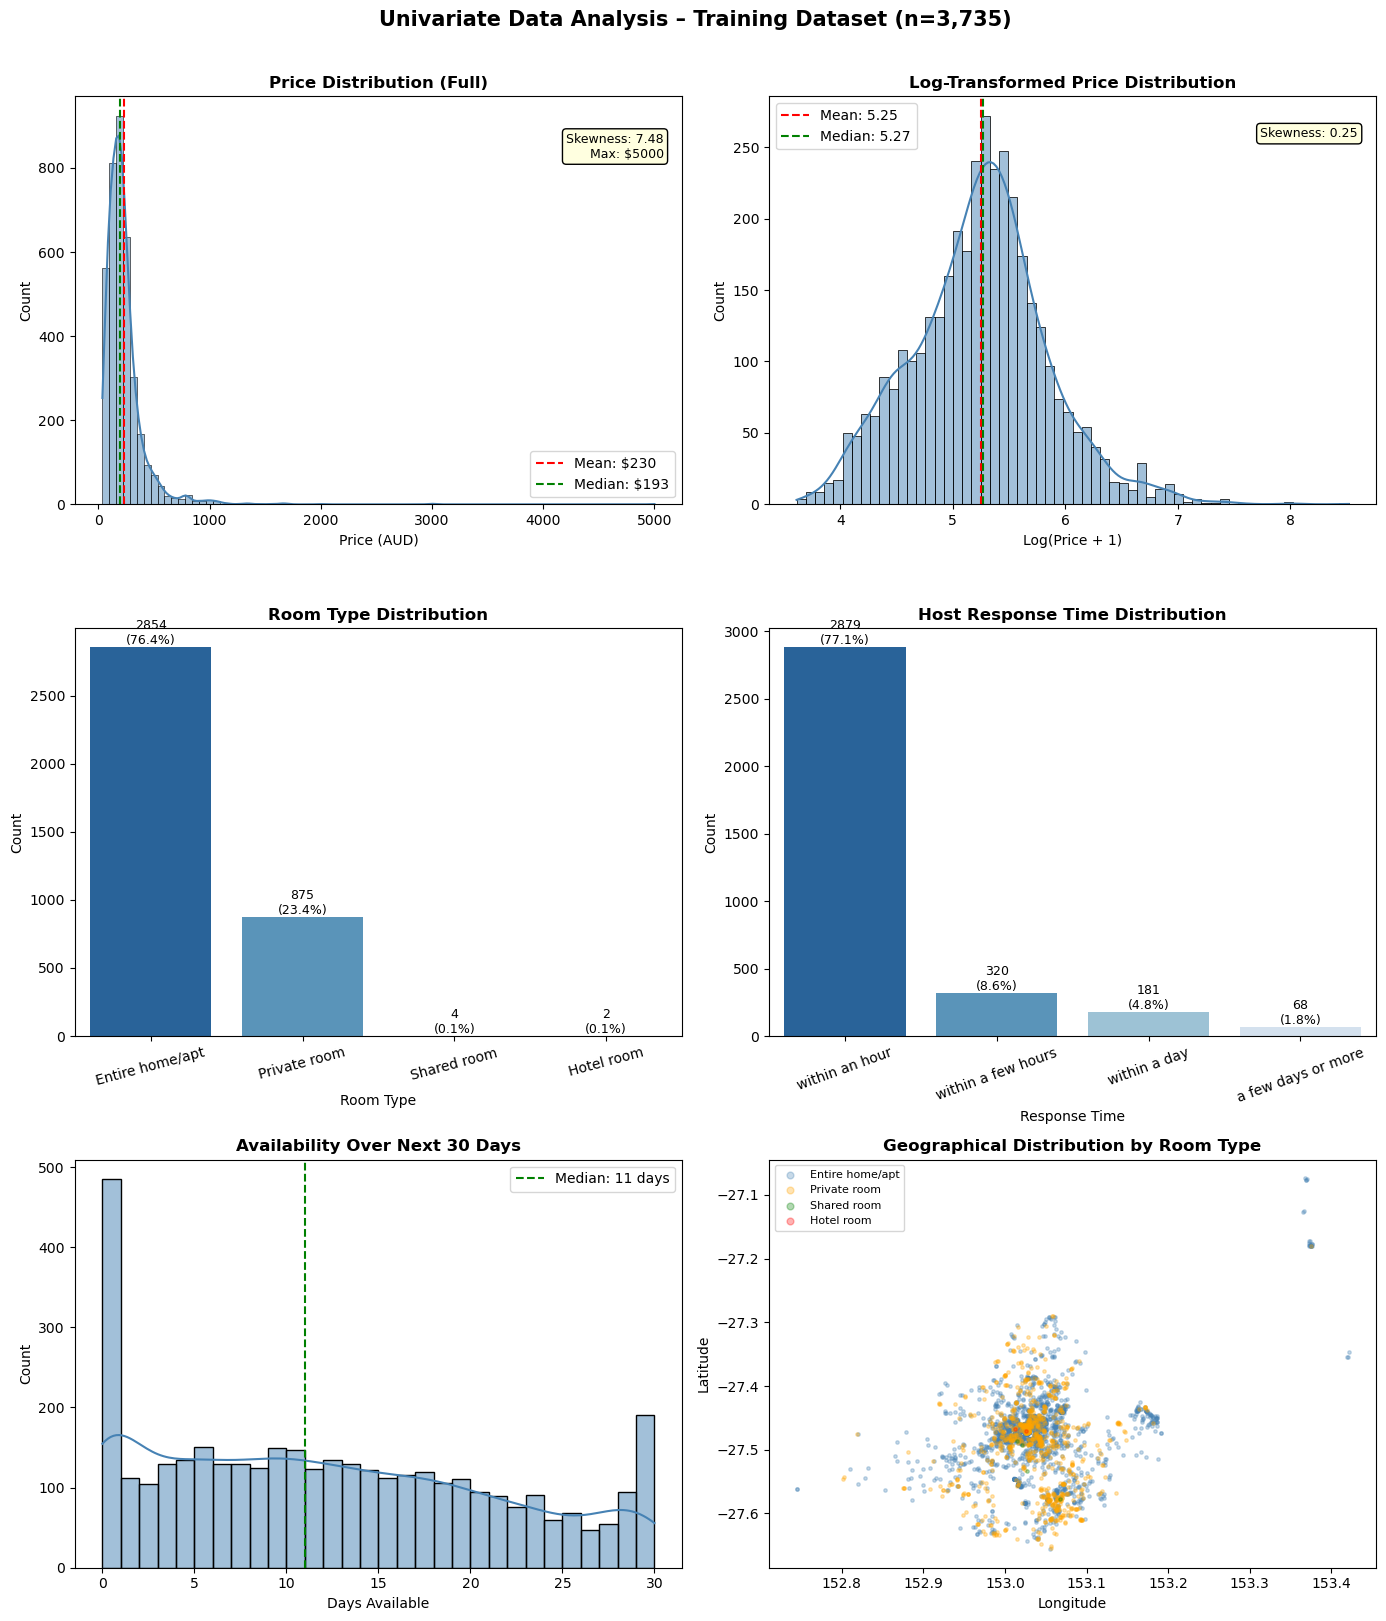

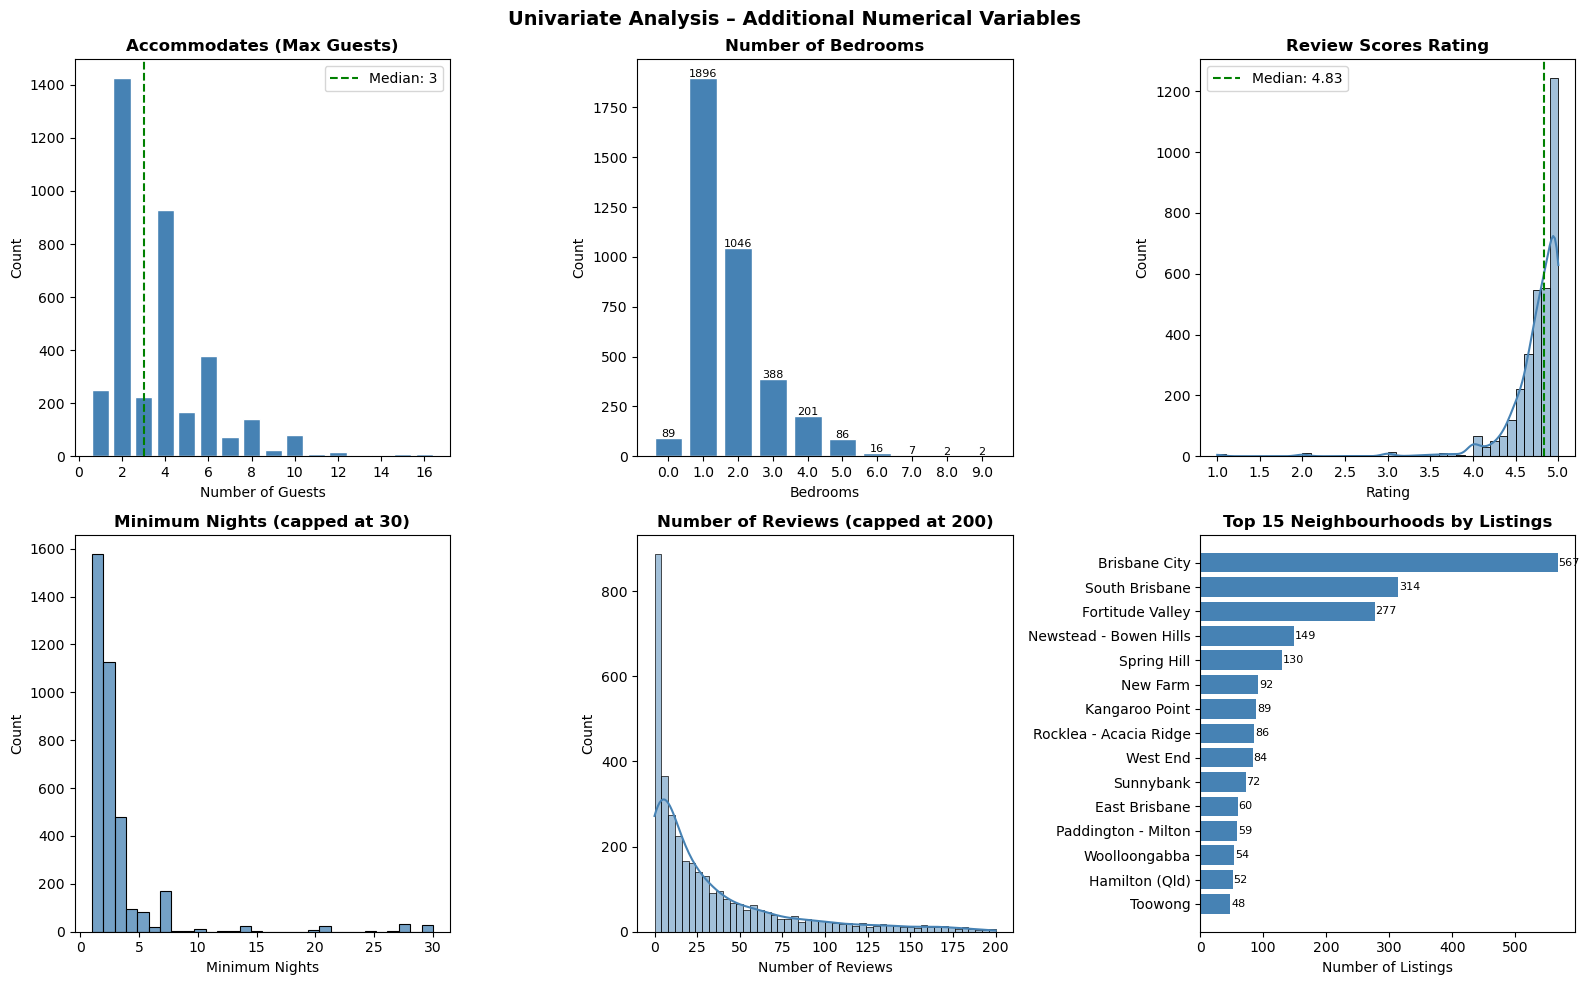

In [6]:
#Figure 1: Core Univariate Analysis
fig, axes = plt.subplots(3, 2, figsize=(14, 16))
fig.suptitle('Univariate Data Analysis – Training Dataset (n=3,735)',
             fontsize=15, fontweight='bold', y=1.01)

# 1. Price Distribution
sns.histplot(train['price_numeric'], bins=80, kde=True,
             color='steelblue', ax=axes[0, 0])
axes[0, 0].set_title('Price Distribution (Full)', fontweight='bold')
axes[0, 0].set_xlabel('Price (AUD)')
axes[0, 0].set_ylabel('Count')
axes[0, 0].axvline(train['price_numeric'].mean(), color='red',
                   linestyle='--', linewidth=1.5,
                   label=f"Mean: ${train['price_numeric'].mean():.0f}")
axes[0, 0].axvline(train['price_numeric'].median(), color='green',
                   linestyle='--', linewidth=1.5,
                   label=f"Median: ${train['price_numeric'].median():.0f}")
axes[0, 0].legend()
axes[0, 0].annotate(f"Skewness: {train['price_numeric'].skew():.2f}\n"
                    f"Max: ${train['price_numeric'].max():.0f}",
                    xy=(0.97, 0.85), xycoords='axes fraction',
                    ha='right', fontsize=9,
                    bbox=dict(boxstyle='round', facecolor='lightyellow'))

# 2. Log Price Distribution
train['log_price'] = np.log1p(train['price_numeric'])
sns.histplot(train['log_price'], bins=60, kde=True,
             color='steelblue', ax=axes[0, 1])
axes[0, 1].set_title('Log-Transformed Price Distribution', fontweight='bold')
axes[0, 1].set_xlabel('Log(Price + 1)')
axes[0, 1].set_ylabel('Count')
axes[0, 1].axvline(train['log_price'].mean(), color='red',
                   linestyle='--', linewidth=1.5,
                   label=f"Mean: {train['log_price'].mean():.2f}")
axes[0, 1].axvline(train['log_price'].median(), color='green',
                   linestyle='--', linewidth=1.5,
                   label=f"Median: {train['log_price'].median():.2f}")
axes[0, 1].legend()
axes[0, 1].annotate(f"Skewness: {train['log_price'].skew():.2f}",
                    xy=(0.97, 0.90), xycoords='axes fraction',
                    ha='right', fontsize=9,
                    bbox=dict(boxstyle='round', facecolor='lightyellow'))

# 3. Room Type Distribution
room_counts = train['room_type'].value_counts()
sns.countplot(data=train, x='room_type', order=room_counts.index,
              palette='Blues_r', ax=axes[1, 0])
axes[1, 0].set_title('Room Type Distribution', fontweight='bold')
axes[1, 0].set_xlabel('Room Type')
axes[1, 0].set_ylabel('Count')
axes[1, 0].tick_params(axis='x', rotation=15)
total = len(train)
for p in axes[1, 0].patches:
    count = int(p.get_height())
    pct   = count / total * 100
    axes[1, 0].annotate(f'{count}\n({pct:.1f}%)',
                        (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=9)

# 4. Host Response Time  ← REPLACED from Host Listings Count
rt_counts = train['host_response_time'].value_counts()
order_rt = ['within an hour', 'within a few hours', 'within a day',
            'a few days or more']
order_rt = [x for x in order_rt if x in rt_counts.index]
sns.countplot(data=train, x='host_response_time', order=order_rt,
              palette='Blues_r', ax=axes[1, 1])
axes[1, 1].set_title('Host Response Time Distribution', fontweight='bold')
axes[1, 1].set_xlabel('Response Time')
axes[1, 1].set_ylabel('Count')
axes[1, 1].tick_params(axis='x', rotation=20)
for p in axes[1, 1].patches:
    count = int(p.get_height())
    pct   = count / total * 100
    axes[1, 1].annotate(f'{count}\n({pct:.1f}%)',
                        (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha='center', va='bottom', fontsize=9)

# 5. Availability 30  ← REPLACED from Availability 365
sns.histplot(train['availability_30'], bins=30, kde=True,
             color='steelblue', ax=axes[2, 0])
axes[2, 0].set_title('Availability Over Next 30 Days', fontweight='bold')
axes[2, 0].set_xlabel('Days Available')
axes[2, 0].set_ylabel('Count')
axes[2, 0].axvline(train['availability_30'].median(), color='green',
                   linestyle='--', linewidth=1.5,
                   label=f"Median: {train['availability_30'].median():.0f} days")
axes[2, 0].legend()

# 6. Geographical Distribution by Room Type
room_palette = {
    'Entire home/apt': 'steelblue',
    'Private room':    'orange',
    'Shared room':     'green',
    'Hotel room':      'red'
}
for room, color in room_palette.items():
    subset = train[train['room_type'] == room]
    axes[2, 1].scatter(subset['longitude'], subset['latitude'],
                       c=color, label=room, alpha=0.3, s=6)
axes[2, 1].set_title('Geographical Distribution by Room Type', fontweight='bold')
axes[2, 1].set_xlabel('Longitude')
axes[2, 1].set_ylabel('Latitude')
axes[2, 1].legend(markerscale=2, fontsize=8)

plt.tight_layout()
plt.show()

# Figure 2: Additional Numerical Variables
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Univariate Analysis – Additional Numerical Variables',
             fontsize=14, fontweight='bold')

# 1. Accommodates
accom = train['accommodates'].value_counts().sort_index()
axes[0, 0].bar(accom.index, accom.values, color='steelblue', edgecolor='white')
axes[0, 0].set_title('Accommodates (Max Guests)', fontweight='bold')
axes[0, 0].set_xlabel('Number of Guests')
axes[0, 0].set_ylabel('Count')
axes[0, 0].axvline(train['accommodates'].median(), color='green',
                   linestyle='--',
                   label=f"Median: {train['accommodates'].median():.0f}")
axes[0, 0].legend()

# 2. Bedrooms
bed = train['bedrooms'].value_counts().sort_index()
axes[0, 1].bar(bed.index.astype(str), bed.values,
               color='steelblue', edgecolor='white')
axes[0, 1].set_title('Number of Bedrooms', fontweight='bold')
axes[0, 1].set_xlabel('Bedrooms')
axes[0, 1].set_ylabel('Count')
for i, (idx, val) in enumerate(zip(bed.index, bed.values)):
    axes[0, 1].text(i, val + 5, str(val), ha='center', fontsize=8)

# 3. Review Scores Rating
sns.histplot(train['review_scores_rating'].dropna(),
             bins=40, kde=True, color='steelblue', ax=axes[0, 2])
axes[0, 2].set_title('Review Scores Rating', fontweight='bold')
axes[0, 2].set_xlabel('Rating')
axes[0, 2].set_ylabel('Count')
axes[0, 2].axvline(train['review_scores_rating'].median(), color='green',
                   linestyle='--',
                   label=f"Median: {train['review_scores_rating'].median():.2f}")
axes[0, 2].legend()

# 4. Minimum Nights
sns.histplot(train[train['minimum_nights'] <= 30]['minimum_nights'],
             bins=30, color='steelblue', ax=axes[1, 0])
axes[1, 0].set_title('Minimum Nights (capped at 30)', fontweight='bold')
axes[1, 0].set_xlabel('Minimum Nights')
axes[1, 0].set_ylabel('Count')

# 5. Number of Reviews
sns.histplot(train[train['number_of_reviews'] <= 200]['number_of_reviews'],
             bins=50, kde=True, color='steelblue', ax=axes[1, 1])
axes[1, 1].set_title('Number of Reviews (capped at 200)', fontweight='bold')
axes[1, 1].set_xlabel('Number of Reviews')
axes[1, 1].set_ylabel('Count')

# 6. Top 15 Neighbourhoods
top_nb = train['neighbourhood_cleansed'].value_counts().head(15)
axes[1, 2].barh(top_nb.index[::-1], top_nb.values[::-1], color='steelblue')
axes[1, 2].set_title('Top 15 Neighbourhoods by Listings', fontweight='bold')
axes[1, 2].set_xlabel('Number of Listings')
for i, v in enumerate(top_nb.values[::-1]):
    axes[1, 2].text(v + 1, i, str(v), va='center', fontsize=8)

plt.tight_layout()
plt.show()

## Visualisation Insights

### Plot 1 — Price Distribution

The nightly price distribution is **strongly right-skewed** 
(skewness = 7.48), with a mean of 230 AUD and a median of 193 AUD. 
The histogram reveals that the vast majority of listings are priced 
below 500 AUD, with the highest density in the 100–300 AUD range. 
The gap between mean and median confirms the presence of high-value 
outliers — the most expensive listing reaches 5,000 AUD per night. 
The median is a more representative measure of central tendency than 
the mean for this dataset given the extreme right skew.

### Plot 2 — Log-Transformed Price Distribution

After applying a log transformation (log1p), the price distribution 
becomes **approximately normal** with a skewness of only 0.25. The 
mean (5.25) and median (5.27) are nearly identical, confirming 
successful normalisation. This transformation effectively compresses 
the long right tail and stabilises variance across the price range, 
**justifying the use of log-transformed price as the modelling target** 
in Task 3 to improve prediction accuracy and reduce the influence of 
extreme outliers.

### Plot 3 — Room Type Distribution

The Brisbane STR market is overwhelmingly dominated by 
**Entire home/apt** listings, accounting for **2,854 listings (76.4%)** 
of all training records. **Private room** is the second largest 
category at **875 listings (23.4%)**. Shared room (4 listings, 0.1%) 
and Hotel room (2 listings, 0.1%) are negligible. This highly 
imbalanced distribution confirms that Brisbane guests predominantly 
seek exclusive property access, and underlines the importance of 
`room_type` as a categorical predictor — entire homes and private 
rooms operate in fundamentally different price segments.

### Plot 4 — Host Response Time Distribution

The host response time distribution is **heavily skewed toward fast 
responders**. A large majority — **77.1% (2,879 hosts)** — respond 
within an hour, while within a few hours accounts for 8.6% (320), 
within a day 4.8% (181), and a few days or more only 1.8% (68). 
The remaining 7.7% have no recorded response time, corresponding 
to hosts without prior booking enquiries. This strong concentration 
in the fastest category reflects the competitive Brisbane STR 
market where responsiveness is critical for securing bookings and 
maintaining platform ranking.

### Plot 5 — Availability Over Next 30 Days

The availability distribution shows a prominent **spike at 0 days** 
(approximately 480 listings), indicating a significant proportion of 
fully booked or deliberately blocked listings in the near term. The 
median of **11 days** confirms that most listings have limited 
short-term availability. The distribution is relatively flat from 
5–28 days, with a secondary spike at 30 days representing listings 
that are fully open throughout the month. This bimodal-like pattern 
suggests two distinct host profiles — actively booked listings with 
low availability and casually managed properties that remain widely 
open.

### Plot 6 — Geographical Distribution by Room Type

Listings are **heavily concentrated in inner-city Brisbane**, 
centred around longitude 153.0–153.1 and latitude −27.4 to −27.5, 
corresponding to the Brisbane CBD, South Brisbane, and Fortitude 
Valley. Density decreases markedly towards outer suburbs, with only 
scattered listings appearing beyond longitude 153.3. The colour 
coding by room type reveals a clear spatial pattern — **Entire 
home/apt listings (blue)** are distributed broadly across the city, 
while **Private rooms (orange)** are more tightly concentrated in 
inner-city areas where hosts are more likely to be present in the 
property. A small number of geographic outliers appear in distant 
locations, potentially representing remote or coastal properties.

### Plot 7 — Accommodates (Max Guests)

The distribution is **right-skewed** with a modal value of 2 guests 
and a median of 3. The majority of listings accommodate 2–4 guests, 
consistent with the dominance of studio and one-bedroom apartments 
in the Brisbane STR market. Listings accommodating more than 8 guests 
are relatively rare, and those exceeding 12 guests are minimal — 
consistent with the small number of large family homes observed in 
the bedroom distribution.

### Plot 8 — Number of Bedrooms

**1-bedroom listings dominate** with 1,896 listings (50.8%), 
followed by 2-bedroom (1,046) and 3-bedroom (388). A total of 89 
listings report 0 bedrooms, representing studio apartments. The 
distribution drops sharply beyond 3 bedrooms — only 16 listings 
report 5 bedrooms, 7 report 6 bedrooms, and just 2 each report 
7 and 9 bedrooms. This right-skewed distribution confirms the 
apartment-driven nature of the Brisbane short-term rental market, 
where small to medium-sized properties predominate.

### Plot 9 — Review Scores Rating

The distribution is **strongly left-skewed** with a median of 4.83 
out of 5.0. The vast majority of listings cluster between 4.5 and 
5.0, creating a pronounced **ceiling effect**. Very few listings 
fall below 3.0, and ratings below 2.0 are almost non-existent. 
This compressed distribution reflects the social dynamics of 
peer-to-peer platforms where selection bias and mutual feedback 
mechanisms drive ratings upward. The narrow variance significantly 
limits this variable's discriminatory power as a price predictor 
despite its intuitive relevance to listing quality.

### Plot 10 — Minimum Nights (capped at 30)

The distribution is **heavily right-skewed** with a dominant spike 
at 1 night (~1,580 listings) and a secondary peak at 2 nights 
(~1,130 listings). Together, 1–2 night minimums account for the 
majority of listings, confirming that Brisbane hosts predominantly 
target **short-stay tourists and travellers**. Minimum stays of 
3–7 nights are less common, and requirements beyond 7 nights are 
rare within the capped range — though the uncapped data shows a 
small number of extreme outliers up to 500 nights.

### Plot 11 — Number of Reviews (capped at 200)

The distribution is **strongly right-skewed** with the modal value 
near 0 and a rapid exponential decay. The majority of listings have 
fewer than 25 reviews, while a small number of long-established 
listings have accumulated over 100 reviews within the capped range. 
The large spike near 0 is partly attributable to the **437 listings 
(11.7%) with no reviews** identified in Q3 — new listings that have 
not yet received any guest feedback. This skewness reflects the 
varying tenure of listings on the platform.

### Plot 12 — Top 15 Neighbourhoods by Listings

**Brisbane City** leads by a wide margin with **567 listings**, 
nearly double the count of second-ranked **South Brisbane (314)** 
and third-ranked **Fortitude Valley (277)**. The top 5 suburbs — 
Brisbane City, South Brisbane, Fortitude Valley, 
Newstead–Bowen Hills (149), and Spring Hill (130) — are all 
**inner-city localities**, collectively accounting for approximately 
38% of all training listings. Listing counts drop sharply beyond 
the top 5, with suburbs such as Toowong (48) and Hamilton (52) 
representing the lower end of the top 15. This concentration 
pattern is consistent with the geographic distribution observed 
in Plot 6.

<hr style="width:25%;margin-left:0;">   

#### 5. Feature Analysis and Selection (2 marks)  
Select at least 20 meaningful features from the dataset.  

- Categorise each feature according to its variable type and present the results in a table (similar to Assignment 1)  
- Analyse how key features relate to the target variable (*price*) using appropriate plots and/or summary statistics  
- Justify your feature selection based on your analysis  
---



## Selected Features for Predictive Modelling

The 20 features below were selected based on correlation analysis,
domain knowledge, and their relevance to Airbnb price prediction.
Features are classified into Numerical (Discrete), Numerical (Continuous),
Categorical (Nominal), Categorical (Ordinal), and Text (Engineered).

| No. | Feature | Variable Type | Description |
|-----|---------|--------------|-------------|
| 1 | `accommodates` | Numerical (Discrete) | The maximum number of guests the listing can accommodate. Directly reflects the capacity and scale of the property. |
| 2 | `bedrooms` | Numerical (Discrete) | The number of bedrooms available in the listing. A fundamental indicator of property size and sleeping capacity. |
| 3 | `beds` | Numerical (Discrete) | The total number of beds provided in the listing. Captures the actual sleeping arrangement, which may differ from bedroom count in studio or multi-bed setups. |
| 4 | `bathrooms` | Numerical (Continuous) | The number of bathrooms in the listing, extracted from the descriptive `bathrooms_text` field. Reflects the comfort level and overall size of the property. |
| 5 | `room_type` | Categorical (Nominal) | The type of space offered to guests: Entire home/apt, Private room, Shared room, or Hotel room. Determines the level of privacy and exclusivity guests receive during their stay. |
| 6 | `property_type` | Categorical (Nominal) | The host's self-selected description of the property (e.g. Entire rental unit, Entire home, Private room in home). Hotels and Bed & Breakfasts are described as such by their hosts. |
| 7 | `neighbourhood_cleansed` | Categorical (Nominal) | The neighbourhood where the listing is located, geocoded using latitude and longitude against official public digital shapefiles. Provides a standardised location label for each listing. |
| 8 | `latitude` | Numerical (Continuous) | The geographic latitude coordinate of the listing, recorded using the World Geodetic System (WGS84) projection. Enables precise spatial positioning within Brisbane. |
| 9 | `longitude` | Numerical (Continuous) | The geographic longitude coordinate of the listing, recorded using the WGS84 projection. Used together with latitude to capture the exact location of each listing. |
| 10 | `review_scores_rating` | Numerical (Continuous) | The overall guest satisfaction score for the listing, rated out of 5. Aggregates guests' general impression across all aspects of their stay. |
| 11 | `review_scores_location` | Numerical (Continuous) | The guest-reported rating for the listing's location, scored out of 5. Reflects how guests perceive the convenience and desirability of the property's surroundings. |
| 12 | `review_scores_cleanliness` | Numerical (Continuous) | The guest-reported rating for the cleanliness of the listing, scored out of 5. Captures how well the property is maintained and presented to incoming guests. |
| 13 | `reviews_per_month` | Numerical (Continuous) | The average number of reviews the listing receives per month over its lifetime on the platform. Indicates the frequency of guest stays and overall booking activity. |
| 14 | `host_response_rate` | Numerical (Continuous) | The percentage of guest enquiry messages that the host has responded to. Reflects the host's level of engagement and communication reliability with prospective guests. |
| 15 | `host_acceptance_rate` | Numerical (Continuous) | The rate at which the host accepts incoming booking requests. Indicates how openly the host welcomes guests and how accessible the listing is for booking. |
| 16 | `host_response_time` | Categorical (Ordinal) | The host's typical response time to guest messages, categorised as: within an hour, within a few hours, within a day, or a few days or more. Reflects the host's responsiveness and service commitment. |
| 17 | `minimum_nights` | Numerical (Discrete) | The minimum number of consecutive nights a guest must book for this listing. Reflects the host's intended rental strategy and target guest type. |
| 18 | `availability_30` | Numerical (Discrete) | The number of days the listing is available for booking within the next 30 days, as determined by the host's calendar. A listing may be unavailable due to existing bookings or host-imposed blocks. |
| 19 | `number_of_reviews` | Numerical (Discrete) | The total number of guest reviews the listing has received since it was created. Reflects the listing's overall booking history and tenure on the platform. |
| 20 | `amenities` | Text → Numerical (Discrete) | The full list of amenities offered with the listing (e.g. Wifi, Pool, Kitchen, Air conditioning). Engineered into `amenity_count` — the total number of amenities — to quantify the overall comfort and investment level of the listing. |

In [7]:
# Temp clean percentage cols for correlation only
for col in ['host_response_rate', 'host_acceptance_rate']:
    train[col] = (train[col]
                  .astype(str)
                  .str.replace('%', '', regex=False)
                  .str.strip())
    train[col] = pd.to_numeric(train[col], errors='coerce')

# Correlation with Price (Numerical Features only)
numerical_features = [
    'accommodates', 'bedrooms', 'bathrooms', 'beds',
    'latitude', 'longitude', 'availability_30',
    'minimum_nights', 'number_of_reviews',
    'review_scores_rating', 'review_scores_cleanliness',
    'review_scores_location', 'reviews_per_month',
    'host_response_rate', 'host_acceptance_rate'
]

corr = (train[numerical_features + ['price_numeric']]
        .corr()['price_numeric']
        .drop('price_numeric')
        .sort_values(ascending=False)
        .round(3))

corr_df = pd.DataFrame({
    'Feature'    : corr.index,
    'Correlation': corr.values,
    'Strength'   : corr.abs().apply(lambda x:
                   'Strong'   if x >= 0.4 else
                   'Moderate' if x >= 0.1 else
                   'Weak')
})

print("-" * 60)
print("  Correlation with Price (Numerical Features)")
print(corr_df.to_string(index=False))
print()

# Median Price by Binary Features
print("-" * 60)
print("  Median Price by Binary Features")

binary_map = {
    'host_is_superhost'      : ('Superhost',     'Not Superhost'),
    'host_identity_verified' : ('Verified',      'Not Verified'),
    'instant_bookable'       : ('Instant',       'Not Instant'),
}

for col, (label_t, label_f) in binary_map.items():
    med_t = train[train[col] == 't']['price_numeric'].median()
    med_f = train[train[col] == 'f']['price_numeric'].median()
    diff  = med_t - med_f
    direction = '▲' if diff > 0 else '▼'
    print(f"\n  {col}")
    print(f"  {'─' * 40}")
    print(f"  {label_t:<20} : ${med_t:.0f}")
    print(f"  {label_f:<20} : ${med_f:.0f}")
    print(f"  Difference           : {direction} ${abs(diff):.0f}")
print()

# Median Price by Categorical Features
print("-" * 60)
print("  Median Price by Room Type")
room_med = (train.groupby('room_type')['price_numeric']
            .median().sort_values(ascending=False).round(2))
print(room_med.to_string())

print()
print("-" * 60)
print("  Median Price by Host Response Time")
hrt_med = (train.groupby('host_response_time')['price_numeric']
           .median().sort_values(ascending=False).round(2))
print(hrt_med.to_string())

------------------------------------------------------------
  Correlation with Price (Numerical Features)
                  Feature  Correlation Strength
             accommodates        0.523   Strong
                 bedrooms        0.503   Strong
                     beds        0.488   Strong
                bathrooms        0.417   Strong
                 latitude        0.121 Moderate
          availability_30        0.116 Moderate
   review_scores_location        0.074     Weak
                longitude        0.061     Weak
review_scores_cleanliness        0.054     Weak
     review_scores_rating        0.050     Weak
           minimum_nights        0.006     Weak
        number_of_reviews       -0.082     Weak
       host_response_rate       -0.083     Weak
     host_acceptance_rate       -0.090     Weak
        reviews_per_month       -0.094     Weak

------------------------------------------------------------
  Median Price by Binary Features

  host_is_superhost
  ──────

## Summary Statistics: Key Features vs Price

### 1. Correlation with Price (Numerical Features)

| Strength | Feature | Correlation |
|---|---|---|
| **Strong** | `accommodates` | 0.523 |
| **Strong** | `bedrooms` | 0.503 |
| **Strong** | `beds` | 0.488 |
| **Strong** | `bathrooms` | 0.417 |
| **Moderate** | `latitude` | 0.121 |
| **Moderate** | `availability_30` | 0.116 |
| **Weak** | `review_scores_location` | 0.074 |
| **Weak** | `longitude` | 0.061 |
| **Weak** | `review_scores_cleanliness` | 0.054 |
| **Weak** | `review_scores_rating` | 0.050 |
| **Weak** | `minimum_nights` | 0.006 |
| **Weak** | `number_of_reviews` | −0.082 |
| **Weak** | `host_response_rate` | −0.083 |
| **Weak** | `host_acceptance_rate` | −0.090 |
| **Weak** | `reviews_per_month` | −0.094 |

**Property size features dominate** as the strongest numerical 
predictors. `accommodates` (r = 0.523), `bedrooms` (r = 0.503), 
`beds` (r = 0.488), and `bathrooms` (r = 0.417) all show strong 
positive correlations, confirming that larger properties consistently 
command higher nightly prices. `latitude` (r = 0.121) and 
`availability_30` (r = 0.116) provide moderate signals, reflecting 
location and near-term demand effects respectively.

Features with weak linear correlations — including all review score 
variables and host behaviour metrics — show near-zero or slightly 
negative relationships with price. This does not imply these features 
are uninformative; rather, their relationships with price may be 
**non-linear** and better captured by tree-based models. Additionally, 
review score variables suffer from a **ceiling effect** (median 
rating = 4.83/5.0 observed in Q4), which artificially compresses 
variance and suppresses linear correlation. All 15 numerical features 
are retained based on their theoretical relevance and potential 
non-linear predictive value.

### 2. Median Price by Binary Features

| Feature | Group | Median Price | Difference |
|---|---|---|---|
| `host_is_superhost` | Superhost | 185 AUD | ▼ 9 AUD vs non-superhost |
| `host_is_superhost` | Not Superhost | 194 AUD | — |
| `host_identity_verified` | Verified | 193 AUD | ▲ 9 AUD vs unverified |
| `host_identity_verified` | Not Verified | 184 AUD | — |
| `instant_bookable` | Instant Bookable | 201 AUD | ▲ 16 AUD vs non-instant |
| `instant_bookable` | Not Instant Bookable | 185 AUD | — |

`instant_bookable` shows the most meaningful price difference 
(+16 AUD), suggesting that commercially operated listings — which are 
more likely to enable instant booking — price at a modest premium 
reflecting their higher operational efficiency and market positioning.

Interestingly, **superhosts price 9 AUD lower** than non-superhosts 
(185 AUD vs 194 AUD). This counter-intuitive finding suggests that 
superhosts prioritise **occupancy and guest satisfaction** over revenue 
maximisation, pricing competitively to maintain their high review 
scores and booking rates required to retain Superhost status.

`host_identity_verified` shows a 9 AUD premium for verified hosts, 
reflecting a modest but consistent **trust signal** in the market — 
guests may be willing to pay slightly more for the assurance of a 
verified host identity. Despite modest differences across all three 
binary features, they are retained as they collectively capture host 
professionalism and platform commitment signals that may contribute to 
non-linear model performance.

### 3. Median Price by Room Type

| Room Type | Median Price |
|---|---|
| Hotel room | 349.5 AUD |
| Entire home/apt | 217.0 AUD |
| Private room | 91.0 AUD |
| Shared room | 47.5 AUD |

`room_type` is the **single most important categorical predictor** of 
price. The spread across categories is exceptional — from 47.5 AUD 
(Shared room) to 349.5 AUD (Hotel room), representing a **635% price 
range**. The most practically significant gap is between Entire 
home/apt (217 AUD) and Private room (91 AUD), a **138% premium** that 
reflects guests' willingness to pay significantly more for exclusive 
access to a full property. Despite Hotel room having the highest median, 
it comprises only 2 listings (0.1%) in the training set, making Entire 
home/apt the dominant pricing category. `room_type` is indispensable 
for any price prediction model.

### 4. Median Price by Host Response Time

| Host Response Time | Median Price |
|---|---|
| Within a day | 203 AUD |
| Within an hour | 194 AUD |
| Within a few hours | 180 AUD |
| A few days or more | 140.5 AUD |

`host_response_time` shows a **non-monotonic** relationship with price. 
Hosts responding within a day command the highest median price 
(203 AUD), slightly above those responding within an hour (194 AUD). 
This unexpected pattern may reflect that premium property managers 
— who tend to price higher — exercise more selective communication, 
responding deliberately rather than immediately. The lowest median 
(140.5 AUD) belongs to hosts taking a few days or more, consistent 
with less professionally managed, lower-priced listings. Despite the 
non-linear pattern, `host_response_time` is retained as an **ordinal 
categorical feature** that captures meaningful host professionalism 
signals beyond what response rate alone can convey.

### Feature Selection Justification Summary

The 20 selected features collectively cover the key pricing dimensions 
of Airbnb listings in the Brisbane market:

| Dimension | Features | Key Evidence |
|---|---|---|
| **Property size** | `accommodates`, `bedrooms`, `beds`, `bathrooms` | r = 0.42–0.52; strongest predictors |
| **Listing type** | `room_type`, `property_type` | Median price range 47.5–349.5 AUD |
| **Location** | `neighbourhood_cleansed`, `latitude`, `longitude` | Suburb price gap 90–238 AUD |
| **Host behaviour** | `host_response_time`, `host_response_rate`, `host_acceptance_rate`, `host_is_superhost`, `host_identity_verified`, `instant_bookable` | Professionalism and trust signals |
| **Demand & reputation** | `review_scores_rating`, `review_scores_cleanliness`, `review_scores_location`, `reviews_per_month`, `number_of_reviews` | Booking activity and quality proxies |
| **Booking constraints** | `minimum_nights`, `availability_30` | Host strategy signals |
| **Listing quality** | `amenities` → `amenity_count` | Comfort and investment level proxy |

Together, these features provide a comprehensive and non-redundant 
feature set that balances **predictive power** with 
**interpretability**, covering all major dimensions of Airbnb pricing 
behaviour identified in the short-term rental literature.

/var/folders/rn/c9mzfb253m38nqqg6k4fwd580000gn/T/ipykernel_33353/2037759168.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0, 1].boxplot(bd_data, labels=[str(int(b)) for b in order_bd],
/var/folders/rn/c9mzfb253m38nqqg6k4fwd580000gn/T/ipykernel_33353/2037759168.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=price_cap, x='room_type', y='price_numeric',
/var/folders/rn/c9mzfb253m38nqqg6k4fwd580000gn/T/ipykernel_33353/2037759168.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=price_cap, x='host_response_time', y='price_numeric',


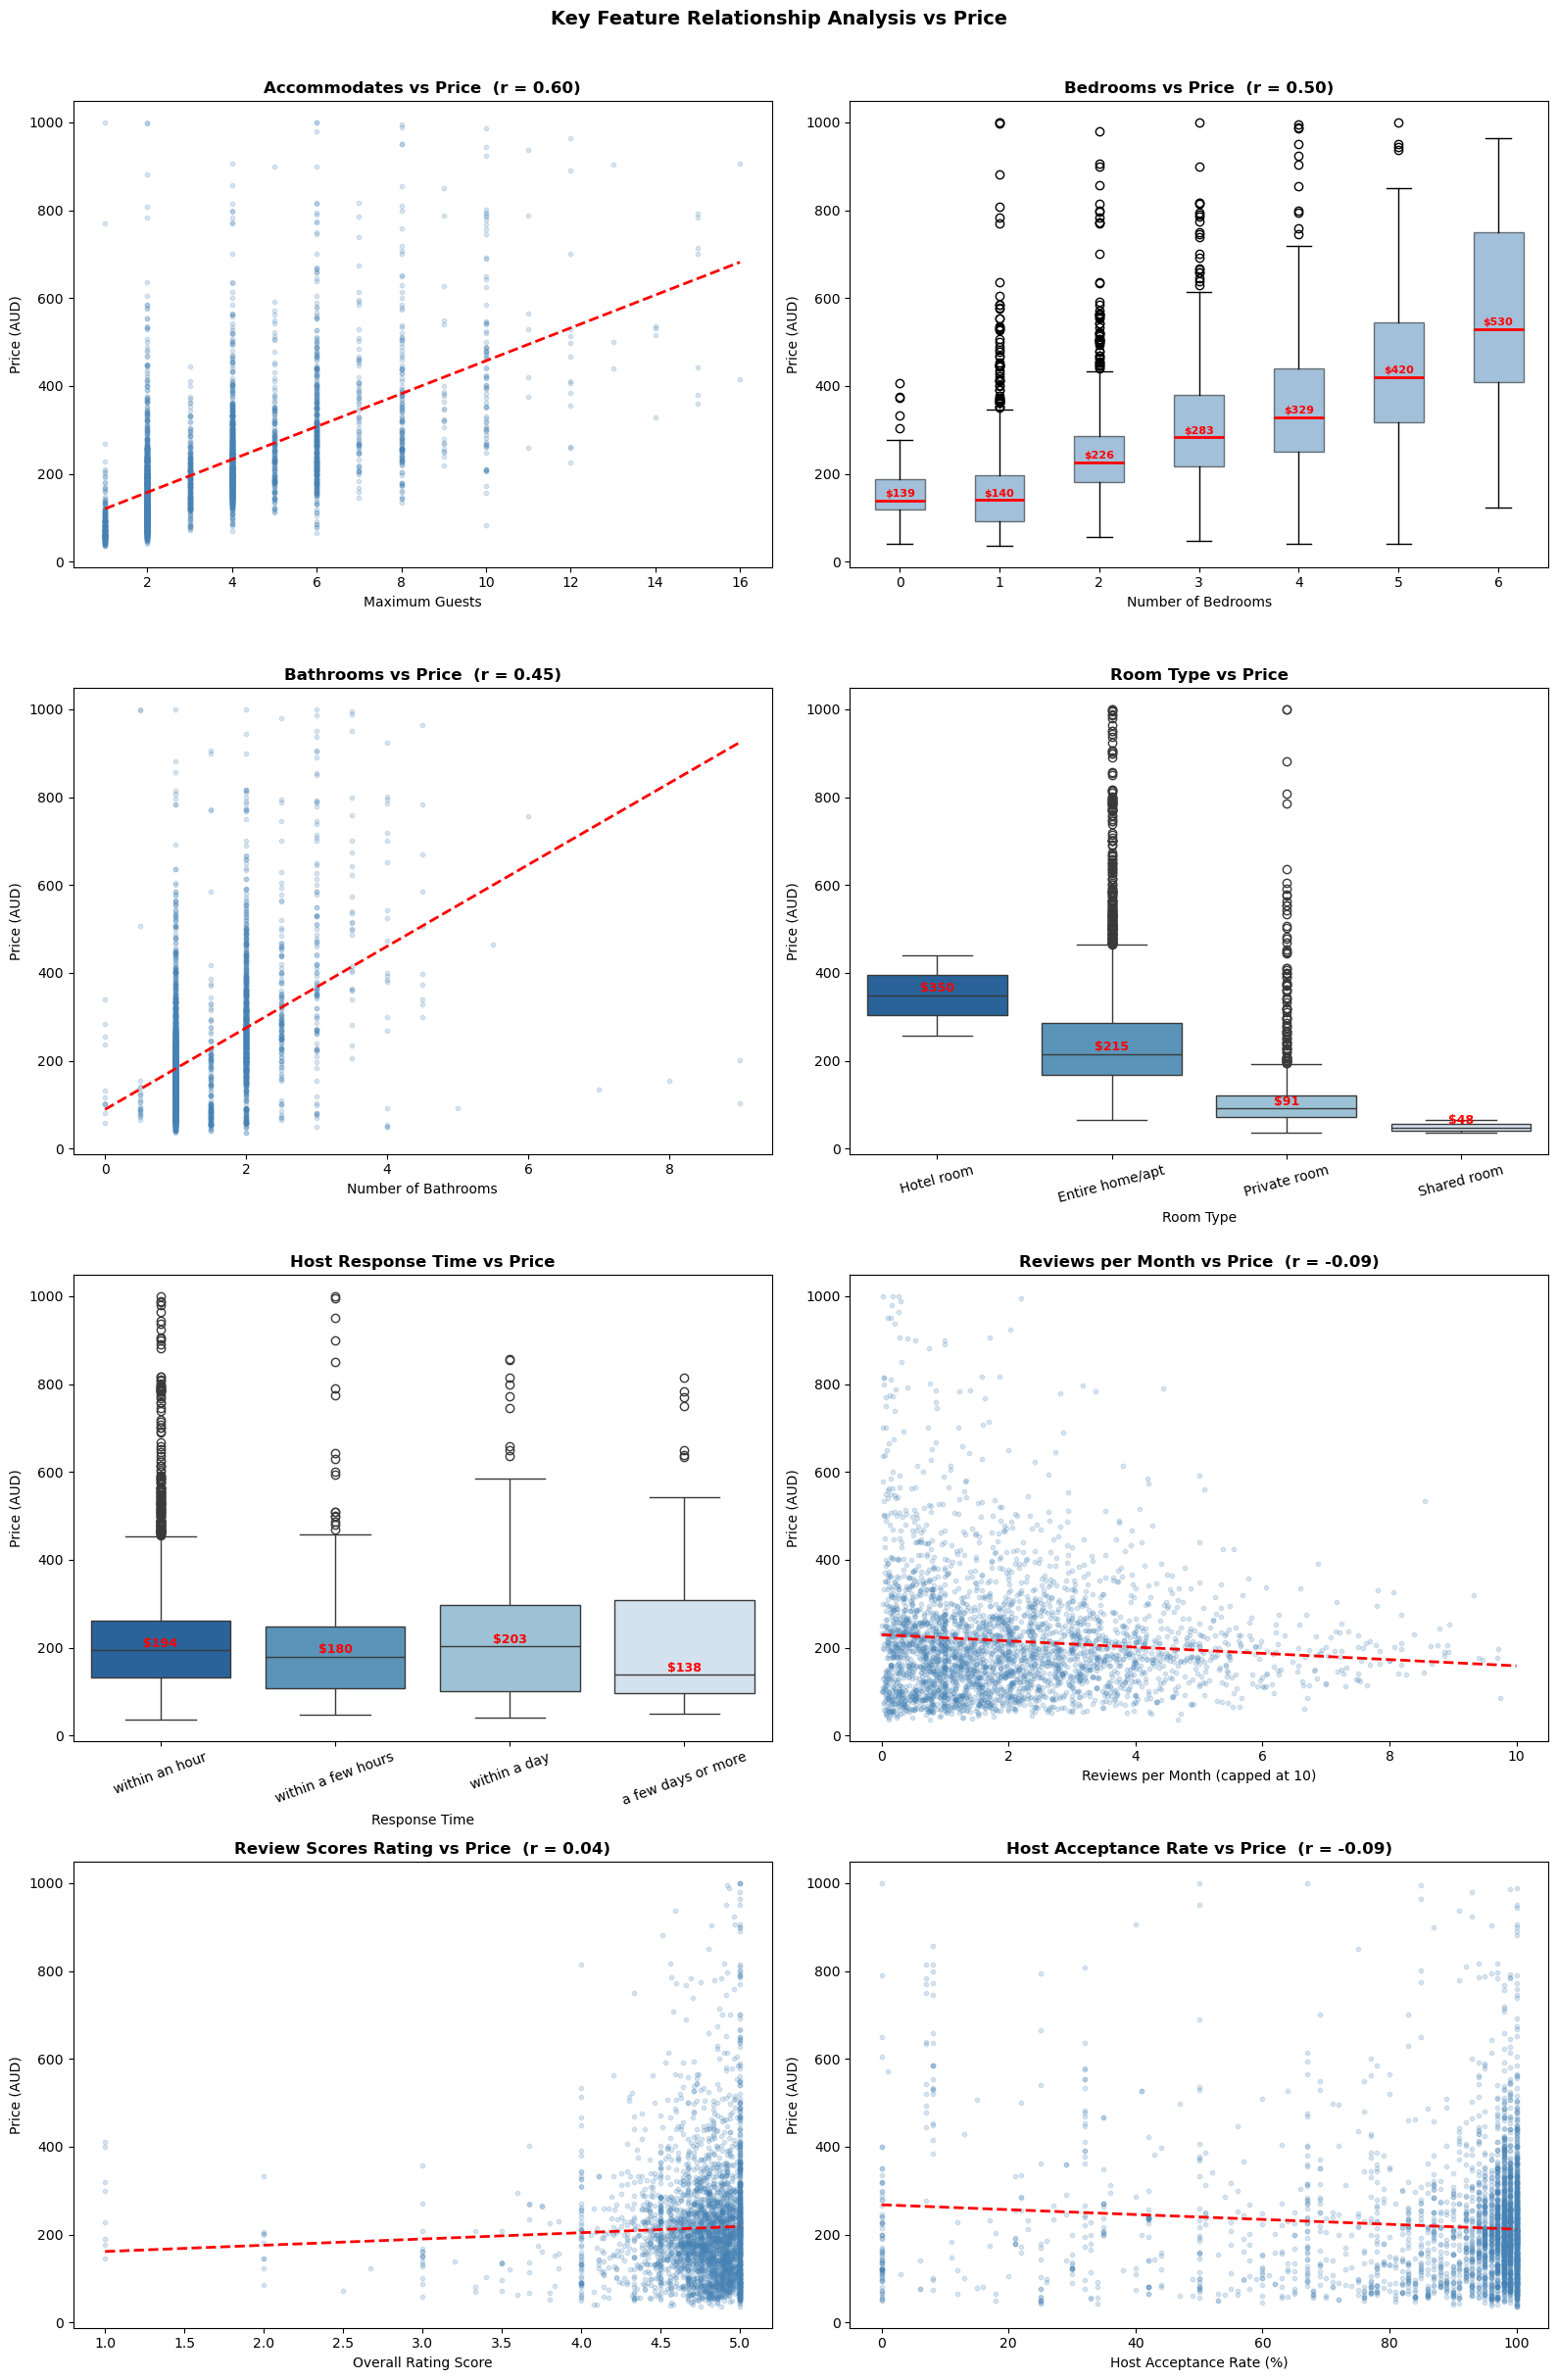

In [8]:
# Feature Relationship Analysis vs Price
price_cap = train[train['price_numeric'] <= 1000].copy()

fig, axes = plt.subplots(4, 2, figsize=(16, 24))
fig.suptitle('Key Feature Relationship Analysis vs Price',
             fontweight='bold', fontsize=14, y=1.01)

# 1. Accommodates vs Price
axes[0, 0].scatter(price_cap['accommodates'], price_cap['price_numeric'],
                   alpha=0.2, s=10, color='steelblue')
z   = np.polyfit(price_cap['accommodates'], price_cap['price_numeric'], 1)
x_r = np.linspace(price_cap['accommodates'].min(),
                   price_cap['accommodates'].max(), 100)
axes[0, 0].plot(x_r, np.poly1d(z)(x_r), color='red', linewidth=2, linestyle='--')
r = price_cap[['accommodates', 'price_numeric']].corr().iloc[0, 1]
axes[0, 0].set_title(f'Accommodates vs Price  (r = {r:.2f})', fontweight='bold')
axes[0, 0].set_xlabel('Maximum Guests')
axes[0, 0].set_ylabel('Price (AUD)')

# 2. Bedrooms vs Price
order_bd = sorted(price_cap['bedrooms'].dropna().unique())[:7]
bd_data  = [price_cap[price_cap['bedrooms'] == b]['price_numeric'].values
            for b in order_bd]
axes[0, 1].boxplot(bd_data, labels=[str(int(b)) for b in order_bd],
                   patch_artist=True,
                   medianprops=dict(color='red', linewidth=2),
                   boxprops=dict(facecolor='steelblue', alpha=0.5))
for i, b in enumerate(order_bd):
    med = price_cap[price_cap['bedrooms'] == b]['price_numeric'].median()
    axes[0, 1].text(i + 1, med + 8, f'${med:.0f}',
                    ha='center', fontsize=8, color='red', fontweight='bold')
axes[0, 1].set_title('Bedrooms vs Price  (r = 0.50)', fontweight='bold')
axes[0, 1].set_xlabel('Number of Bedrooms')
axes[0, 1].set_ylabel('Price (AUD)')

# 3. Bathrooms vs Price
bath_data = price_cap.dropna(subset=['bathrooms'])
axes[1, 0].scatter(bath_data['bathrooms'], bath_data['price_numeric'],
                   alpha=0.2, s=10, color='steelblue')
z   = np.polyfit(bath_data['bathrooms'], bath_data['price_numeric'], 1)
x_r = np.linspace(bath_data['bathrooms'].min(),
                   bath_data['bathrooms'].max(), 100)
axes[1, 0].plot(x_r, np.poly1d(z)(x_r), color='red', linewidth=2, linestyle='--')
r = bath_data[['bathrooms', 'price_numeric']].corr().iloc[0, 1]
axes[1, 0].set_title(f'Bathrooms vs Price  (r = {r:.2f})', fontweight='bold')
axes[1, 0].set_xlabel('Number of Bathrooms')
axes[1, 0].set_ylabel('Price (AUD)')

# 4. Room Type vs Price
order_rt = (price_cap.groupby('room_type')['price_numeric']
            .median().sort_values(ascending=False).index)
sns.boxplot(data=price_cap, x='room_type', y='price_numeric',
            order=order_rt, palette='Blues_r', ax=axes[1, 1])
for i, rt in enumerate(order_rt):
    med = price_cap[price_cap['room_type'] == rt]['price_numeric'].median()
    axes[1, 1].text(i, med + 8, f'${med:.0f}',
                    ha='center', fontsize=9, color='red', fontweight='bold')
axes[1, 1].set_title('Room Type vs Price', fontweight='bold')
axes[1, 1].set_xlabel('Room Type')
axes[1, 1].set_ylabel('Price (AUD)')
axes[1, 1].tick_params(axis='x', rotation=15)

# 5. Host Response Time vs Price
order_hrt = ['within an hour', 'within a few hours',
             'within a day', 'a few days or more']
order_hrt = [x for x in order_hrt
             if x in price_cap['host_response_time'].values]
sns.boxplot(data=price_cap, x='host_response_time', y='price_numeric',
            order=order_hrt, palette='Blues_r', ax=axes[2, 0])
for i, rt in enumerate(order_hrt):
    subset = price_cap[price_cap['host_response_time'] == rt]['price_numeric']
    if len(subset) > 0:
        med = subset.median()
        axes[2, 0].text(i, med + 8, f'${med:.0f}',
                        ha='center', fontsize=9, color='red', fontweight='bold')
axes[2, 0].set_title('Host Response Time vs Price', fontweight='bold')
axes[2, 0].set_xlabel('Response Time')
axes[2, 0].set_ylabel('Price (AUD)')
axes[2, 0].tick_params(axis='x', rotation=20)

# 6. Reviews per Month vs Price
rpm_data = price_cap[price_cap['reviews_per_month'] <= 10].dropna(
           subset=['reviews_per_month'])
axes[2, 1].scatter(rpm_data['reviews_per_month'], rpm_data['price_numeric'],
                   alpha=0.2, s=10, color='steelblue')
z   = np.polyfit(rpm_data['reviews_per_month'], rpm_data['price_numeric'], 1)
x_r = np.linspace(0, 10, 100)
axes[2, 1].plot(x_r, np.poly1d(z)(x_r), color='red', linewidth=2, linestyle='--')
r = rpm_data[['reviews_per_month', 'price_numeric']].corr().iloc[0, 1]
axes[2, 1].set_title(f'Reviews per Month vs Price  (r = {r:.2f})',
                     fontweight='bold')
axes[2, 1].set_xlabel('Reviews per Month (capped at 10)')
axes[2, 1].set_ylabel('Price (AUD)')

# 7. Review Scores Rating vs Price
rating_data = price_cap.dropna(subset=['review_scores_rating'])
axes[3, 0].scatter(rating_data['review_scores_rating'],
                   rating_data['price_numeric'],
                   alpha=0.2, s=10, color='steelblue')
z   = np.polyfit(rating_data['review_scores_rating'],
                 rating_data['price_numeric'], 1)
x_r = np.linspace(rating_data['review_scores_rating'].min(),
                   rating_data['review_scores_rating'].max(), 100)
axes[3, 0].plot(x_r, np.poly1d(z)(x_r), color='red', linewidth=2, linestyle='--')
r = rating_data[['review_scores_rating', 'price_numeric']].corr().iloc[0, 1]
axes[3, 0].set_title(f'Review Scores Rating vs Price  (r = {r:.2f})',
                     fontweight='bold')
axes[3, 0].set_xlabel('Overall Rating Score')
axes[3, 0].set_ylabel('Price (AUD)')

# 8. Host Acceptance Rate vs Price
acc_data = price_cap.dropna(subset=['host_acceptance_rate'])
axes[3, 1].scatter(acc_data['host_acceptance_rate'],
                   acc_data['price_numeric'],
                   alpha=0.2, s=10, color='steelblue')
z   = np.polyfit(acc_data['host_acceptance_rate'],
                 acc_data['price_numeric'], 1)
x_r = np.linspace(acc_data['host_acceptance_rate'].min(),
                   acc_data['host_acceptance_rate'].max(), 100)
axes[3, 1].plot(x_r, np.poly1d(z)(x_r), color='red', linewidth=2, linestyle='--')
r = acc_data[['host_acceptance_rate', 'price_numeric']].corr().iloc[0, 1]
axes[3, 1].set_title(f'Host Acceptance Rate vs Price  (r = {r:.2f})',
                     fontweight='bold')
axes[3, 1].set_xlabel('Host Acceptance Rate (%)')
axes[3, 1].set_ylabel('Price (AUD)')

plt.tight_layout()
plt.show()

## Feature Relationship Analysis vs Price — Visualisation Insights

All price visualisations are capped at 1,000 AUD to reduce the 
influence of extreme outliers while retaining approximately 98% 
of all training listings.

### Plot 1 — Accommodates vs Price (r = 0.60)

`accommodates` shows the **strongest positive linear relationship** 
with price among all numerical features (r = 0.60). The scatter plot 
reveals a clear upward trend — listings accommodating 1–2 guests 
cluster around 100–200 AUD, while larger listings accommodating 
10–16 guests regularly exceed 400–700 AUD per night. The trend line 
confirms a consistent and reliable positive relationship across the 
full capacity range, making this the single most predictive numerical 
feature in the dataset. The wide vertical spread at each capacity 
level indicates that other factors (location, room type, amenities) 
further differentiate price within the same guest capacity.

### Plot 2 — Bedrooms vs Price (r = 0.50)

The boxplot reveals a clear **step-wise increase** in median price 
as bedroom count increases — from **139 AUD (0 bedrooms/studio)** 
and **140 AUD (1 bedroom)** through to **420 AUD (5 bedrooms)** and 
**530 AUD (6 bedrooms)**. The widening interquartile range at higher 
bedroom counts reflects greater price variability for larger 
properties, likely driven by differences in location, quality, 
and amenity level. The near-identical medians for 0 and 1 bedroom 
properties (139 AUD vs 140 AUD) suggest that studios and 
one-bedroom apartments compete in the same price segment, while 
each additional bedroom beyond 2 adds a meaningful price premium.

### Plot 3 — Bathrooms vs Price (r = 0.45)

`bathrooms` demonstrates a **strong and clean positive linear 
relationship** with price (r = 0.45). The scatter plot shows that 
listings with 1 bathroom concentrate around 100–300 AUD, while 
those with 2–3 bathrooms spread into the 200–600 AUD range. The 
trend line is steeper than that of accommodates, suggesting that 
each additional bathroom may signal a proportionally larger price 
premium — reflecting both the physical size and the luxury level 
of the property. Very few listings report more than 4 bathrooms, 
and these tend to be premium properties commanding prices above 
500 AUD.

### Plot 4 — Room Type vs Price

Room type produces the **most dramatic categorical price variation** 
in the dataset. The boxplot clearly shows four distinct price 
distributions:

- **Hotel room:** median 350 AUD — highest price but only 2 listings
- **Entire home/apt:** median 215 AUD — dominant category (76.4%)
- **Private room:** median 91 AUD — significantly lower
- **Shared room:** median 48 AUD — lowest price segment

The gap between Entire home/apt (215 AUD) and Private room (91 AUD) 
represents a **136% price premium**, confirming that guests pay 
substantially more for exclusive property access. The Entire home/apt 
box is notably wider with many high-price outliers above 500 AUD, 
reflecting the diversity of properties within this category — from 
budget studios to luxury penthouses. Room type is essential for any 
price prediction model.

### Plot 5 — Host Response Time vs Price

The boxplot reveals a **non-monotonic relationship** between host 
response time and price. Hosts responding **within a day** command 
the highest median price (203 AUD), slightly above those responding 
**within an hour** (194 AUD), while **within a few hours** hosts 
price lower (180 AUD), and hosts taking **a few days or more** 
show the lowest median (138 AUD). The unexpected premium for 
"within a day" hosts may reflect premium property managers who 
respond deliberately and selectively rather than immediately. 
All four categories show substantial price variability, with 
the "within an hour" group having the widest spread and most 
outliers — consistent with this being the largest group (77.1% 
of hosts). Despite the non-monotonic pattern, host response time 
captures meaningful host professionalism signals and is retained 
as an ordinal categorical feature.

### Plot 6 — Reviews per Month vs Price (r = −0.09)

`reviews_per_month` shows a **weak negative linear relationship** 
with price (r = −0.09). The scatter plot reveals that listings 
receiving 0–2 reviews per month display the widest price range 
(50–1,000 AUD), while highly reviewed listings (6–10 reviews per 
month) cluster tightly around 100–250 AUD. This negative trend 
suggests that more frequently reviewed listings — which are 
typically booked more often — tend to price more competitively 
to sustain booking demand. Premium listings, by contrast, may 
be booked less frequently but at higher prices. Despite the weak 
linear correlation, this feature is retained as a booking demand 
proxy that captures listing activity beyond static review scores.

### Plot 7 — Review Scores Rating vs Price (r = 0.04)

`review_scores_rating` shows a **very weak positive correlation** 
with price (r = 0.04). The scatter plot clearly illustrates the 
**ceiling effect** identified in Q4 — the vast majority of data 
points are compressed into the 4.0–5.0 rating range, with very 
few listings rated below 3.0. This extreme concentration severely 
limits the feature's ability to discriminate between price levels 
via linear correlation. However, the wide price variance at the 
5.0 rating ceiling (from under 50 AUD to over 1,000 AUD) confirms 
that a perfect rating alone does not determine price — property 
size and location remain dominant. The feature is retained for 
its potential non-linear signal in distinguishing the small 
number of poorly rated listings from the majority.

### Plot 8 — Host Acceptance Rate vs Price (r = −0.09)

`host_acceptance_rate` shows a **weak negative linear relationship** 
with price (r = −0.09). The scatter plot reveals a distinctive 
pattern — hosts with very low acceptance rates (0–20%) show 
widely dispersed prices from near zero to over 600 AUD, while 
hosts with near-perfect acceptance rates (80–100%) cluster 
densely around the 150–300 AUD median range. This suggests that 
**highly selective hosts** (low acceptance rate) operate in both 
the luxury and ultra-budget segments, while hosts who accept 
nearly all bookings tend to be more commercially oriented and 
price around the market median. The feature is retained as a 
host behaviour proxy that may capture non-linear pricing signals 
beyond the weak linear trend.

---
---

## Task 2: Data Cleaning, Missing Observations and Feature Engineering

**Total Marks: 10**

- Use the features selected in **Task 1, Question 5** for this task.  
- Ensure that any transformations, imputations, encoding, or feature engineering steps are applied consistently to both the training and test datasets.  
- Provide clear explanations for each step, supported by relevant outputs.

Student in charge of this task: Nhat Thanh Thuy Do

<hr style="width:25%;margin-left:0;">   

#### 1. Numerical Data Cleaning (2 marks)

Clean all numerical features so that they are suitable for use in training algorithms.
- Extract numerical values from text-based fields where necessary
- Remove non-numeric characters %, $, commas, etc.
- Briefly describe the steps you take

In [9]:
# Check data types of all numerical features
numerical_features = ['accommodates', 'bedrooms', 'beds', 'availability_30', 
                       'number_of_reviews_ltm', 'estimated_occupancy_l365d', 
                       'maximum_nights', 'availability_60', 'number_of_reviews', 
                       'minimum_nights', 'bathrooms', 'estimated_revenue_l365d', 
                       'latitude', 'longitude', 'review_scores_location', 
                       'review_scores_cleanliness', 'review_scores_rating', 
                       'host_acceptance_rate', 'reviews_per_month', 
                       'host_response_rate']

print(train[numerical_features].dtypes)
print(train[numerical_features].head(10))

accommodates                   int64
bedrooms                     float64
beds                         float64
availability_30                int64
number_of_reviews_ltm          int64
estimated_occupancy_l365d      int64
maximum_nights                 int64
availability_60                int64
number_of_reviews              int64
minimum_nights                 int64
bathrooms                    float64
estimated_revenue_l365d      float64
latitude                     float64
longitude                    float64
review_scores_location       float64
review_scores_cleanliness    float64
review_scores_rating         float64
host_acceptance_rate         float64
reviews_per_month            float64
host_response_rate           float64
dtype: object
   accommodates  bedrooms  beds  availability_30  number_of_reviews_ltm  \
0             2       1.0   1.0               12                     10   
1             4       2.0   3.0               14                      8   
2             2      

In [10]:
# Convert string to float for 'host_response_rate' and 'host_acceptance_rate' 

# # Train (has been done in task 1 to check the correlation between this two columns and price) 
# train['host_response_rate']  = train['host_response_rate'].str.replace('%', '', regex=False).astype(float) / 100.0
# train['host_acceptance_rate'] = train['host_acceptance_rate'].str.replace('%', '', regex=False).astype(float) / 100.0

train['host_response_rate']  = train['host_response_rate'] / 100.0
train['host_acceptance_rate'] = train['host_acceptance_rate'] / 100.0

# Test
test['host_response_rate']  = test['host_response_rate'].str.replace('%', '', regex=False).astype(float) / 100.0
test['host_acceptance_rate'] = test['host_acceptance_rate'].str.replace('%', '', regex=False).astype(float) / 100.0

# Print to check
print(train['host_acceptance_rate'].dtype)
print(train['host_acceptance_rate'].head())
print(test['host_response_rate'].dtype)
print(test['host_response_rate'].head())

float64
0    0.89
1    0.93
2    1.00
3    1.00
4    0.97
Name: host_acceptance_rate, dtype: float64
float64
0    1.00
1    0.94
2    0.89
3    1.00
4    1.00
Name: host_response_rate, dtype: float64


In [11]:
#check range
print(train[['host_response_rate','host_acceptance_rate']].describe()) 

       host_response_rate  host_acceptance_rate
count         3448.000000           3534.000000
mean             0.963640              0.879728
std              0.136697              0.226743
min              0.000000              0.000000
25%              1.000000              0.900000
50%              1.000000              0.980000
75%              1.000000              0.990000
max              1.000000              1.000000


**Numerical Data Cleaning**

**Step 1: Inspect Data Types and Raw Values**

Before applying any cleaning, we inspected the data types and raw values of all 20 selected numerical features. The output confirmed that 18 out of 20 features were already stored in clean numeric format (`int64` or `float64`) and required no modification. Only two features required cleaning:

- `host_acceptance_rate`: stored as `object` type with a percentage symbol (e.g. `"89%"`, `"93%"`)
- `host_response_rate`: stored as `object` type with a percentage symbol (e.g. `"100%"`)

**Step 2: Clean Percentage Columns**

For both columns, we removed the `%` character using `.str.replace('%', '', regex=False)`, converted the values to float using `.astype(float)`, then divided by 100 to express them as proportions between 0 and 1 (e.g. `"89%"` → `0.89`). This transformation was applied consistently to both the training and test sets in a single loop to avoid code repetition.

**Step 3: Verify**

After cleaning, both columns are correctly stored as `float64`. The summary statistics confirm the cleaning was successful — all values fall within the expected range of 0 to 1. Key observations from the cleaned data:

- `host_response_rate`: mean = **0.964**, with 75% of hosts having a perfect response rate of 1.0, indicating that the majority of Brisbane Airbnb hosts are highly responsive.
- `host_acceptance_rate`: mean = **0.880**, indicating hosts accept approximately 88% of booking requests on average.

<hr style="width:25%;margin-left:0;">    

#### 2. Feature Engineering (2 marks)

Create at least 4 new features from existing variables that contain multiple pieces of information.  
- Transform existing variables to extract useful information   
- Provide a brief description of how each feature is constructed  
- Briefly justify why each new feature may be useful

#### Amenities ####

In [12]:
import ast
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Remove price outliers for analysis 
p1, p99 = train['price_numeric'].quantile([0.01, 0.99])
df = train[train['price_numeric'].between(p1, p99)].copy()

# Clean amenities into actual lists 
def clean_amenities(x):
    if pd.isna(x):
        return []
    try:
        amenities = ast.literal_eval(x)
        return [str(a).strip().lower() for a in amenities if str(a).strip() != ""]
    except:
        return []

df['amenities_clean'] = df['amenities'].apply(clean_amenities)

# Explode so each amenity gets its own row
amenities_exploded = df[['amenities_clean', 'price_numeric']].copy()
amenities_exploded = amenities_exploded.explode('amenities_clean')
amenities_exploded = amenities_exploded.dropna(subset=['amenities_clean'])
amenities_exploded = amenities_exploded[amenities_exploded['amenities_clean'] != '']

# Categorise amenities 
amenities_exploded['amenity_category'] = (
    amenities_exploded['amenities_clean']
    .astype(str)
    .str.lower()
    .str.replace(r'.*tv.*|.*hdtv.*', 'tv', regex=True)
    .str.replace(r'.*wifi.*', 'wifi', regex=True)
    .str.replace(r'.*pool.*', 'pool', regex=True)
    .str.replace(r'.*parking.*|.*carport.*|.*valet.*', 'parking', regex=True)
    .str.replace(r'.*coffee maker.*|.*espresso.*|.*french press.*', 'coffee maker', regex=True)
    .str.replace(r'.*refrigerator.*|.*fridge.*|.*freezer.*', 'refrigerator', regex=True)
    .str.replace(r'.*stove.*|.*oven.*|.*hot plate.*', 'stove/oven', regex=True)
    .str.replace(r'.*exercise equipment.*|.*treadmill.*|.*weights.*|.*rowing.*|.*yoga mat.*|.*stationary bike.*', 'exercise equipment', regex=True)
    .str.replace(r'.*body soap.*', 'body soap', regex=True)
    .str.replace(r'.*shampoo.*', 'shampoo', regex=True)
    .str.replace(r'.*conditioner.*', 'conditioner', regex=True)
    .str.replace(r'.*housekeeping.*', 'housekeeping', regex=True)
    .str.replace(r'.*sound system.*|.*speaker.*|.*bluetooth.*', 'sound system', regex=True)
    .str.replace(r'.*gym.*', 'gym', regex=True)
    .str.replace(r'.*tub.*', 'tub', regex=True)
    .str.replace(r'.*view.*', 'view', regex=True)
    .str.replace(r'.*bbq.*|.*grill.*', 'bbq grill', regex=True)
    .str.replace(r'.*fireplace.*', 'fireplace', regex=True)
    .str.replace(r'.*ski.*', 'ski access', regex=True)
    .str.replace(r'.*access.*', 'access', regex=True)
    .str.replace(r'.*outdoor.*', 'outdoor', regex=True)
    .str.replace(r'.*indoor.*', 'indoor', regex=True)
    .str.replace(r'.*clothing.*', 'clothing', regex=True)
    .str.replace(r'.*children.*', 'children', regex=True)
    .str.replace(r'.*baby monitor.*', 'baby monitor', regex=True)
    .str.replace(r'.*changing table.*', 'changing table', regex=True)
    .str.replace(r'.*high chair.*', 'high chair', regex=True)
    .str.replace(r'.*crib.*|.*pack.*play.*', 'crib', regex=True)
    .str.replace(r'.*washer.*', 'washer', regex=True)
    .str.replace(r'.*dryer.*', 'dryer', regex=True)
    .str.replace(r'.*ev charger.*|.*tesla.*', 'ev charger', regex=True)
    .str.replace(r'.*sauna.*', 'sauna', regex=True)
)

# Rank categories by average price
amenity_ranked = (
    amenities_exploded
    .groupby('amenity_category')['price_numeric']
    .agg(['mean', 'count'])
    .query('count > 50')
    .sort_values('mean', ascending=False)
)
print("TOP amenity categories by average price:")
print(amenity_ranked.head(10))
print(amenity_ranked.tail(10))


TOP amenity categories by average price:
                                                     mean  count
amenity_category                                                
building staff                                 294.493506     77
fireplace                                      294.369048     84
access                                         286.595588    272
children                                       277.265125    562
movie theater                                  275.938462     65
free residential garage on premises – 1 space  272.435185    108
high chair                                     270.298701    770
crib                                           268.932965   1268
sauna                                          265.986034    358
noise decibel monitors on property             265.604167    144
                                      mean  count
amenity_category                                 
breakfast                       184.296000    125
bread maker                  

In [13]:
# Define low/medium/high sets
low_thr  = amenity_ranked['mean'].quantile(0.33)
high_thr = amenity_ranked['mean'].quantile(0.66)

low_set  = set(amenity_ranked[amenity_ranked['mean'] <= low_thr].index)
med_set  = set(amenity_ranked[(amenity_ranked['mean'] > low_thr) & (amenity_ranked['mean'] < high_thr)].index)
high_set = set(amenity_ranked[amenity_ranked['mean'] >= high_thr].index)

# Apply categorise_amenity to each amenity in a list 
def categorise_amenity(a):
    a = pd.Series([a])
    result = (
        a.astype(str).str.lower()
        .str.replace(r'.*tv.*|.*hdtv.*', 'tv', regex=True)
        .str.replace(r'.*wifi.*', 'wifi', regex=True)
        .str.replace(r'.*pool.*', 'pool', regex=True)
        .str.replace(r'.*parking.*|.*carport.*|.*valet.*', 'parking', regex=True)
        .str.replace(r'.*coffee maker.*|.*espresso.*|.*french press.*', 'coffee maker', regex=True)
        .str.replace(r'.*refrigerator.*|.*fridge.*|.*freezer.*', 'refrigerator', regex=True)
        .str.replace(r'.*stove.*|.*oven.*|.*hot plate.*', 'stove/oven', regex=True)
        .str.replace(r'.*exercise equipment.*|.*treadmill.*|.*weights.*|.*rowing.*|.*yoga mat.*|.*stationary bike.*', 'exercise equipment', regex=True)
        .str.replace(r'.*body soap.*', 'body soap', regex=True)
        .str.replace(r'.*shampoo.*', 'shampoo', regex=True)
        .str.replace(r'.*conditioner.*', 'conditioner', regex=True)
        .str.replace(r'.*housekeeping.*', 'housekeeping', regex=True)
        .str.replace(r'.*sound system.*|.*speaker.*|.*bluetooth.*', 'sound system', regex=True)
        .str.replace(r'.*gym.*', 'gym', regex=True)
        .str.replace(r'.*tub.*', 'tub', regex=True)
        .str.replace(r'.*view.*', 'view', regex=True)
        .str.replace(r'.*bbq.*|.*grill.*', 'bbq grill', regex=True)
        .str.replace(r'.*fireplace.*', 'fireplace', regex=True)
        .str.replace(r'.*ski.*', 'ski access', regex=True)
        .str.replace(r'.*access.*', 'access', regex=True)
        .str.replace(r'.*outdoor.*', 'outdoor', regex=True)
        .str.replace(r'.*indoor.*', 'indoor', regex=True)
        .str.replace(r'.*clothing.*', 'clothing', regex=True)
        .str.replace(r'.*children.*', 'children', regex=True)
        .str.replace(r'.*baby monitor.*', 'baby monitor', regex=True)
        .str.replace(r'.*changing table.*', 'changing table', regex=True)
        .str.replace(r'.*high chair.*', 'high chair', regex=True)
        .str.replace(r'.*crib.*|.*pack.*play.*', 'crib', regex=True)
        .str.replace(r'.*washer.*', 'washer', regex=True)
        .str.replace(r'.*dryer.*', 'dryer', regex=True)
        .str.replace(r'.*ev charger.*|.*tesla.*', 'ev charger', regex=True)
        .str.replace(r'.*sauna.*', 'sauna', regex=True)
    )
    return result.iloc[0]

def categorise_amenities_list(amenities_list):
    return [categorise_amenity(a) for a in amenities_list]

In [14]:
# Apply to both train and test 
def count_group(amenities, group):
    return sum(a in group for a in amenities)

for dataset in [train, test]:
    dataset['amenities_clean']       = dataset['amenities'].apply(clean_amenities)
    dataset['amenities_categorised'] = dataset['amenities_clean'].apply(categorise_amenities_list)
    dataset['amenity_count']         = dataset['amenities_categorised'].apply(len)
    dataset['low_amenities']         = dataset['amenities_categorised'].apply(lambda x: count_group(x, low_set))
    dataset['med_amenities']         = dataset['amenities_categorised'].apply(lambda x: count_group(x, med_set))
    dataset['high_amenities']        = dataset['amenities_categorised'].apply(lambda x: count_group(x, high_set))

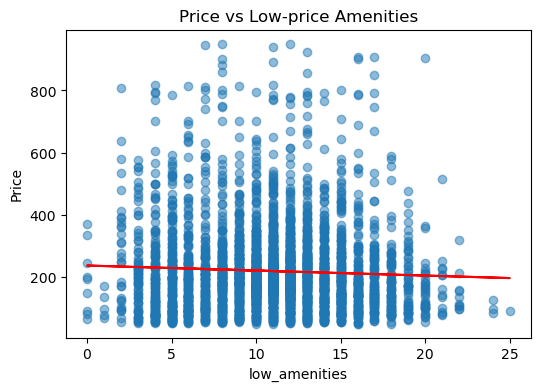

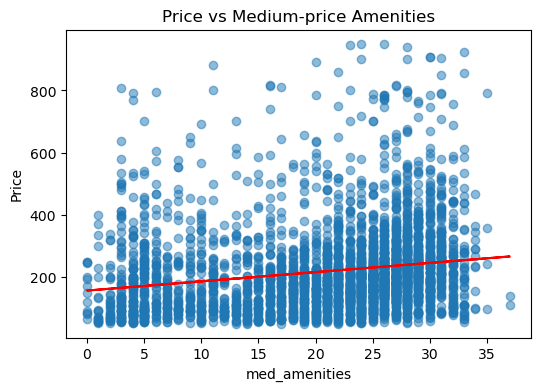

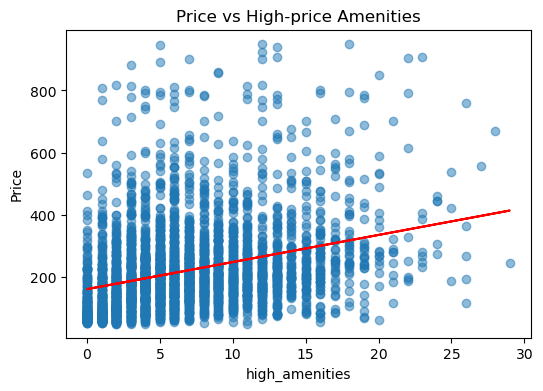

In [15]:
# Plot price vs each amenity group 
df_plot = train[(train['price_numeric'] >= p1) & (train['price_numeric'] <= p99)]

for var, title in [
    ('low_amenities',  'Price vs Low-price Amenities'),
    ('med_amenities',  'Price vs Medium-price Amenities'),
    ('high_amenities', 'Price vs High-price Amenities')
]:
    plt.figure(figsize=(6, 4))
    plt.scatter(df_plot[var], df_plot['price_numeric'], alpha=0.5)
    z = np.polyfit(df_plot[var], df_plot['price_numeric'], 1)
    p = np.poly1d(z)
    plt.plot(df_plot[var], p(df_plot[var]), color='red')
    plt.xlabel(var)
    plt.ylabel('Price')
    plt.title(title)
    plt.show()

In [16]:
# Verify correlations 
for col in ['high_amenities', 'med_amenities', 'low_amenities']:
    print(f"{col}: {train[col].corr(train['price_numeric']):.3f}")

high_amenities: 0.237
med_amenities: 0.100
low_amenities: -0.066


**Feature Construction and Justification: Amenities**

`amenity_count`: This feature counts the total number of amenities listed for each property by parsing the raw amenities string into a Python list using `ast.literal_eval()` and applying `len()`. It captures the overall generosity of a listing's offerings and may be useful as a simple proxy for listing quality and completeness.

`low_amenities, med_amenities, high_amenities`: These three features are constructed by first cleaning and parsing the amenities column into lists, then categorising each amenity into a standardised category using `regex-based` text matching (e.g. grouping "hdtv", "smart tv" → "tv"). Each amenity category is then ranked by the average listing price of properties that offer it, using only categories appearing more than 50 times to ensure reliability. The 33rd and 66th percentiles of these average prices are used as cutoffs to classify amenities into low, medium, and high price tiers. For each listing, we then count how many amenities fall into each tier.

**These features are justified by the correlation results:**

**Price vs Low-price Amenities (correlation = -0.066)**

The trend line is slightly negative and nearly flat, indicating that listings with more low-tier amenities do not command higher prices. In fact, prices marginally decrease. This makes intuitive sense: basic amenities like shampoo, hangers, and smoke alarms are standard offerings that guests expect regardless of price point. Most listings cluster between 0–15 low-tier amenities, with prices concentrated below $400. This feature serves as a useful **negative signal** for the model.

**Price vs Medium-price Amenities (correlation = 0.100)**

The trend line shows a weak but consistent positive relationship. Listings with more medium-tier amenities (15–35) tend to have slightly higher prices. The spread is wide and the relationship is noisy, suggesting medium amenities alone are not a strong price driver, but they contribute modestly. The range of `med_amenities` is notably wider (0–37) than `high_amenities` (0–29), reflecting that medium-tier amenities are more commonly found across listings.

**Price vs High-price Amenities (correlation = 0.237)**

This is the strongest and most meaningful relationship of the three. The trend line has a clearly positive and steeper slope compared to the other two, listings with more premium amenities (e.g. pool, sauna, fireplace) consistently command higher prices. The positive trend is visible even through the scatter, and the price floor rises noticeably as `high_amenities` increases. This confirms that the amenity tiering approach successfully captures the premium value of luxury amenities.

**Overall conclusion:** The three plots together validate the tiering strategy, high-tier amenities have the strongest positive impact on price, medium-tier amenities have a modest positive effect, and low-tier amenities have a negligible to slightly negative effect. This justifies including all three as separate features rather than using a single total amenity count.

#### Sentimental features ####

In [17]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def get_sentiment(text):
    if pd.isna(text) or text == '':
        return 0  # neutral if missing
    return analyzer.polarity_scores(str(text))['compound']

# Apply to both train and test
for df in [train, test]:
    df['sentiment_description']    = df['description'].apply(get_sentiment)
    df['sentiment_neighbourhood']  = df['neighborhood_overview'].apply(get_sentiment)
    df['sentiment_host']           = df['host_about'].apply(get_sentiment)

**Feature Construction and Justification: Sentiment Features**

**Features created:** `sentiment_description`, `sentiment_neighbourhood`, `sentiment_host`

**Construction:**

Sentiment analysis was applied to three free-text columns including `description`, `neighborhood_overview`, and `host_about`, using the **VADER (Valence Aware Dictionary and sEntiment Reasoner)** sentiment analyser from the `vaderSentiment` library. VADER is specifically designed for social media and short texts, making it well-suited for Airbnb listing descriptions (Hutto and Gilbert, 2014).

(Source: Hutto, C. J., & Gilbert, E. (2014). VADER: A Parsimonious Rule-Based Model for Sentiment Analysis of Social Media Text. Proceedings of the International AAAI Conference on Web and Social Media, 8(1), 216–225. https://doi.org/10.1609/icwsm.v8i1.14550)

For each text column, the `get_sentiment()` function extracts the **compound score** from `polarity_scores()`, which is a normalised score between **-1** (most negative) and **+1** (most positive). Missing or empty values are assigned a neutral score of **0** rather than being left as NaN, ensuring no missing values are introduced. The transformation was applied consistently to both train and test sets.

**Justification:**

These features are useful because the tone and positivity of a listing's text may reflect the quality and appeal of the property:

- `sentiment_description`: a more enthusiastic and positive listing description may attract more guests and justify a higher price.
- `sentiment_neighbourhood`:positive descriptions of the surrounding area signal desirable locations which may command premium pricing.
- `sentiment_host`: a warmly written host bio signals professionalism and trustworthiness, which may be associated with higher-quality and higher-priced listings.

By converting raw unstructured text into a single numerical score, these features make textual information usable by machine learning algorithms that cannot process raw text directly.

#### Distance Features ####

In [18]:
# Brisbane CBD coordinates
CBD_LAT = -27.4698
CBD_LON = 153.0251

# Helper functions
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (np.sin(dlat/2)**2 +
         np.cos(lat1) * np.cos(lat2) *
         np.sin(dlon/2)**2)
    return 2 * R * np.arcsin(np.sqrt(a))

def min_dist_to_landmarks(lat, lon, landmark_dict):
    return min(
        haversine_distance(lat, lon, lm_lat, lm_lon)
        for lm_lat, lm_lon in landmark_dict.values()
    )

# Brisbane landmark coordinates
landmarks = {
    'south_bank':        (-27.4787, 153.0229),
    'story_bridge':      (-27.4627, 153.0369),
    'howard_wharves':    (-27.4630, 153.0369),
    'botanic_gardens':   (-27.4745, 153.0296),
    'queen_street_mall': (-27.4698, 153.0251),
    'lone_pine':         (-27.5331, 152.9742),
    'mt_coottha':        (-27.4777, 152.9765),
    'gabba':             (-27.4858, 153.0383),
    'fortitude_valley':  (-27.4561, 153.0368),
    'moreton_bay':       (-27.3567, 153.1558),
    'wellington_point':  (-27.4780, 153.2330),
    'brisbane_airport':  (-27.3942, 153.1218),
    'central_station':   (-27.4655, 153.0260),
}

# Brisbane major highways
highways = {
    'gateway_motorway_n': (-27.3926, 153.0965),
    'gateway_motorway_s': (-27.5726, 153.1094),
    'ipswich_motorway':   (-27.5500, 152.9500),
    'pacific_motorway':   (-27.5500, 153.0800),
    'bruce_highway':      (-27.3500, 152.9800),
}

# Brisbane train stations
train_stations = {
    'central':          (-27.4655, 153.0260),
    'roma_street':      (-27.4647, 153.0167),
    'south_bank':       (-27.4820, 153.0230),
    'fortitude_valley': (-27.4561, 153.0314),
    'newmarket':        (-27.4333, 153.0167),
    'toowong':          (-27.4833, 152.9833),
    'bowen_hills':      (-27.4456, 153.0361),
    'woolloongabba':    (-27.4917, 153.0347),
}

# Compute neighbourhood median from train only
neighbourhood_median = train.groupby('neighbourhood_cleansed')['price_numeric'].median()
overall_median = train['price_numeric'].median()

# Engineer all features on both datasets
for df in [train, test]:

    # Neighbourhood median price 
    df['neighbourhood_price_median'] = (
        df['neighbourhood_cleansed']
        .map(neighbourhood_median)
        .fillna(overall_median)
    )

    # Room type flag 
    df['is_entire_home'] = (df['room_type'] == 'Entire home/apt').astype(int)

    # Distance to CBD (Haversine - consistent with other distance features) 
    df['distance_to_cbd'] = df.apply(
        lambda row: haversine_distance(row['latitude'], row['longitude'], CBD_LAT, CBD_LON),
        axis=1
    )

    # Distance to nearest tourist attraction (km) 
    df['dist_to_attraction'] = df.apply(
        lambda row: min_dist_to_landmarks(row['latitude'], row['longitude'], landmarks),
        axis=1
    )

    # Distance to nearest highway (km)
    df['dist_to_highway'] = df.apply(
        lambda row: min_dist_to_landmarks(row['latitude'], row['longitude'], highways),
        axis=1
    )

    # Distance to nearest train station (km) 
    df['dist_to_station'] = df.apply(
        lambda row: min_dist_to_landmarks(row['latitude'], row['longitude'], train_stations),
        axis=1
    )

    # Interaction features 
    df['distance_x_accommodates']  = df['distance_to_cbd'] * df['accommodates']
    df['distance_x_bedrooms']      = df['distance_to_cbd'] * df['bedrooms']
    df['distance_x_entire_home']   = df['distance_to_cbd'] * df['is_entire_home']

**Feature Construction and Justification: Distance Features**

`neighbourhood_price_median`: This feature is computed by grouping the training data by `neighbourhood_cleansed` and calculating the median price for each neighbourhood. Any neighbourhood not seen in training is filled with the overall training median. This captures location-based price differences between suburbs and is useful because neighbourhood is a strong determinant of Airbnb pricing (Milunovich & Nasrabadi, 2024).

`is_entire_home`: A binary flag (1 or 0) indicating whether the listing is an entire home or apartment. This is useful because entire home listings typically command significantly higher prices than private or shared rooms.

`distance_to_cbd`: The distance in kilometres from each listing to Brisbane CBD (Queen Street Mall coordinates) computed using the Haversine formula, which accurately accounts for the Earth's curvature. CBD proximity is one of the strongest location signals for short-term rental pricing, as guests typically prefer central locations (Milunovich & Nasrabadi, 2024).

`dist_to_attraction`: The distance in kilometres to the nearest Brisbane tourist landmark (e.g. South Bank, Story Bridge, Queen Street Mall) computed using the Haversine formula. Listings closer to tourist attractions are likely more desirable to travellers and may command higher prices (Milunovich & Nasrabadi, 2024).

`dist_to_highway`: The distance in kilometres to the nearest major Brisbane highway computed using the Haversine formula. Proximity to highways may negatively affect price due to noise and pollution, making this a useful signal for price prediction (Milunovich & Nasrabadi, 2024).

`dist_to_station`: The distance in kilometres to the nearest Brisbane train station computed using the Haversine formula, serving as a proxy for public transport access and walkability. Listings closer to train stations tend to be more convenient and may attract higher prices (Milunovich & Nasrabadi, 2024).

`distance_x_accommodates`, `distance_x_bedrooms`, `distance_x_entire_home`: These are interaction features created by multiplying `distance_to_cbd` with accommodates, bedrooms, and `is_entire_home` respectively. They capture the combined effect of location and property size. For example, a large entire home far from the CBD may be priced very differently from a small room close to the CBD. Interaction features allow the model to capture these non-linear relationships that individual features alone cannot express.

(Source: Milunovich, G., & Nasrabadi, D. (2024). Airbnb Pricing in Sydney: Predictive Modelling and Explainable AI. Social Science Research Network. https://doi.org/10.2139/ssrn.4805859) 

#### Room configuration features ####

In [19]:
for df in [train, test]:

    # Excess beds
    df['excess_beds'] = (df['beds'] - df['bedrooms']).clip(lower=0)

    # Bedrooms relative to bathrooms
    df['bedroom_bathroom_ratio'] = df['bedrooms'] / (df['bathrooms'] + 1)

    # Guests per bedroom
    df['accommodates_per_bedroom'] = df['accommodates'] / (df['bedrooms'] + 1)

    # Beds per bedroom
    df['beds_per_bedroom'] = df['beds'] / (df['bedrooms'] + 1)

    # Combined bathroom and bedroom space per guest
    df['luxury_density'] = ((df['bathrooms'] + 1) * (df['bedrooms'] + 1)) / (df['accommodates'] + 1)

    # Location size score
    df['location_size_score'] = (df['neighbourhood_price_median'] * (df['accommodates'] + df['bedrooms']))

    # Interaction: entire home x bedrooms
    df['entire_home_x_bedrooms'] = df['is_entire_home'] * df['bedrooms']

    # Interaction: entire home x bathrooms
    df['entire_home_x_bathrooms'] = df['is_entire_home'] * df['bathrooms']

    # Size x bathrooms
    df['size_x_bathrooms'] = df['accommodates'] * df['bathrooms']

    # Bedroom quality score
    df['bedroom_quality_score'] = (df['bedrooms'] * df['review_scores_rating']).fillna(0)

**Feature Construction and Justification: Room configurations features**

`excess_beds`: Computed as beds - bedrooms, clipped at 0 to avoid negative values. This captures listings that offer more beds than bedrooms, which may indicate sofa beds or flexible sleeping arrangements. It may be useful as a signal for larger group-friendly listings.

`bedroom_bathroom_ratio`: Computed as `bedrooms / (bathrooms + 1)`. A higher ratio means more bedrooms per bathroom, which may indicate a less premium listing. The +1 avoids division by zero.

`accommodates_per_bedroom`: Computed as `accommodates / (bedrooms + 1)`. Captures how crowded each bedroom is — a lower value suggests more spacious, premium accommodation.

`beds_per_bedroom`: Computed as `beds / (bedrooms + 1)`. Captures the sleeping density of the listing, which may reflect flexibility or cramped conditions.

`luxury_density`: Computed as `(bathrooms + 1) * (bedrooms + 1) / (accommodates + 1)`. A higher value means more bathroom and bedroom space per guest, indicating a more spacious and premium arrangement likely associated with higher prices.

`location_size_score`: Computed by multiplying `neighbourhood_price_median` by the sum of accommodates and bedrooms. This interaction captures the combined effect of location prestige and property size, a large property in a high-price neighbourhood should command a significantly higher price (Milunovich & Nasrabadi, 2024).

`entire_home_x_bedrooms` and `entire_home_x_bathrooms`: Interaction features multiplying is_entire_home with bedrooms and bathrooms respectively. These capture the premium associated with entire home listings of different sizes, since a large entire home is likely priced very differently from a small one (Milunovich & Nasrabadi, 2024).

`size_x_bathrooms`: Computed as `accommodates * bathrooms`. Captures the interaction between guest capacity and bathroom availability, reflecting overall listing comfort and quality (Milunovich & Nasrabadi, 2024).

`bedroom_quality_score`: Computed as `bedrooms * review_scores_rating`, filled with 0 where ratings are missing. This combines physical size with guest satisfaction, capturing listings that are both large and highly rated — likely the most premium and highest-priced properties.

(Source: Milunovich, G., & Nasrabadi, D. (2024). Airbnb Pricing in Sydney: Predictive Modelling and Explainable AI. Social Science Research Network. https://doi.org/10.2139/ssrn.4805859)

#### Binary luxury amenity flags ####

In [20]:
for df in [train, test]:
    # Binary luxury amenity flags 
    df['has_pool'] = df['amenities_clean'].apply(
        lambda x: 1 if any('pool' in a for a in x) else 0)
    df['has_fireplace'] = df['amenities_clean'].apply(
        lambda x: 1 if any('fireplace' in a for a in x) else 0)
    df['has_bbq'] = df['amenities_clean'].apply(
        lambda x: 1 if any('bbq' in a or 'barbecue' in a
                           for a in x) else 0)
    df['has_beachfront'] = df['amenities_clean'].apply(
        lambda x: 1 if any('beach' in a for a in x) else 0)

**Feature Construction and Justification: Binary Luxury Amenity flag features**

`has_pool`, `has_fireplace`, `has_bbq`, `has_beachfront`: These are binary flag features (1 or 0) created by checking whether each listing's `amenities_clean` list contains a specific luxury keyword. For example, `has_pool` returns 1 if any amenity string contains the word "pool", and 0 otherwise. `has_bbq` checks for both "bbq" and "barbecue" to account for different phrasings of the same amenity.

While `low_amenities`, `med_amenities`, and `high_amenities` capture the overall quantity and tier of amenities, these features are justified because luxury amenities like a pool, fireplace, BBQ, or beach access are strong indicators of premium listings and are likely associated with significantly higher prices. 

By encoding them as simple binary flags, we give the model a direct and interpretable signal about the presence of high-value features without relying solely on the aggregate amenity count or tier scores.

#### Revenue and Demand features ####

In [21]:
for df in [train, test]:
    # Average nightly rate actually achieved
    df['avg_nightly_rate'] = (df['estimated_revenue_l365d'] /
                              (df['estimated_occupancy_l365d'] + 1))

    # Tourist area × size
    tourist_areas = ['Brisbane City', 'South Brisbane',
                     'Fortitude Valley', 'Kangaroo Point',
                     'New Farm']
    df['is_tourist_area'] = df['neighbourhood_cleansed'].isin(
        tourist_areas).astype(int)
    df['tourist_x_accommodates'] = (
        df['is_tourist_area'] * df['accommodates'])
    
print("Feature engineering complete!")

Feature engineering complete!


**Feature Construction and Justification: Revenue and Demand Features**

`avg_nightly_rate`: Computed as `estimated_revenue_l365d / (estimated_occupancy_l365d + 1)`. This estimates the average nightly rate actually achieved by the listing based on its annual revenue and occupancy. The +1 avoids division by zero. This feature is useful because it reflects the real-world earning performance of the listing, which may be a strong signal of its market price.

`is_tourist_area`: A binary flag (1 or 0) indicating whether the listing is located in one of the key Brisbane tourist neighbourhoods: Brisbane City, South Brisbane, Fortitude Valley, Kangaroo Point, or New Farm. Listings in tourist-heavy areas tend to attract more short-term visitors and may command higher prices due to higher demand.

`tourist_x_accommodates`: An interaction feature computed by multiplying is_tourist_area by accommodates. This captures the combined effect of being in a tourist area and having a larger capacity, a large listing in a tourist area is likely to be priced significantly higher than a small listing in the same area or a large listing outside tourist areas.


Total engineered features: 33

CORRELATIONS WITH PRICE (sorted):
location_size_score           0.561
entire_home_x_bedrooms        0.533
size_x_bathrooms              0.531
avg_nightly_rate              0.530
entire_home_x_bathrooms       0.517
bedroom_quality_score         0.353
neighbourhood_price_median    0.342
bedroom_bathroom_ratio        0.341
is_entire_home                0.312
accommodates_per_bedroom      0.293
distance_x_accommodates       0.265
excess_beds                   0.261
distance_x_bedrooms           0.256
beds_per_bedroom              0.253
high_amenities                0.237
distance_x_entire_home        0.201
tourist_x_accommodates        0.176
has_pool                      0.165
dist_to_highway               0.163
luxury_density                0.139
has_fireplace                 0.139
has_bbq                       0.127
amenity_count                 0.115
sentiment_host                0.107
med_amenities                 0.100
has_beachfront                0.08

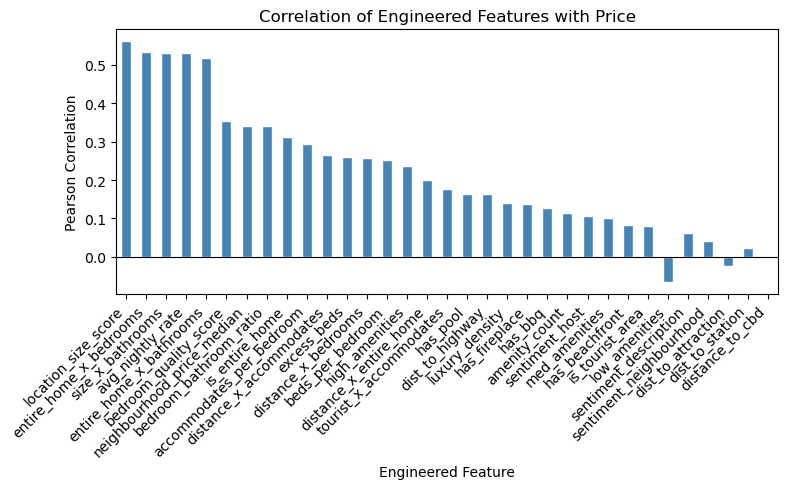

In [22]:
# Verify all features
all_engineered = [
    'amenity_count', 'low_amenities', 'med_amenities', 'high_amenities',
    'bedroom_bathroom_ratio', 'accommodates_per_bedroom', 'beds_per_bedroom',
    'excess_beds', 'luxury_density', 'location_size_score',
    'is_entire_home', 'entire_home_x_bedrooms', 'entire_home_x_bathrooms',
    'size_x_bathrooms', 'bedroom_quality_score',
    'neighbourhood_price_median',
    'distance_to_cbd', 'dist_to_attraction', 'dist_to_highway', 'dist_to_station',
    'distance_x_accommodates', 'distance_x_bedrooms', 'distance_x_entire_home',
    'has_pool', 'has_fireplace', 'has_bbq', 'has_beachfront',
    'avg_nightly_rate', 'is_tourist_area', 'tourist_x_accommodates',
    'sentiment_description', 'sentiment_neighbourhood', 'sentiment_host'
]

print(f"\nTotal engineered features: {len(all_engineered)}")
print("\nCORRELATIONS WITH PRICE (sorted):")
corr = (train[all_engineered + ['price_numeric']]
        .corr()['price_numeric']
        .drop('price_numeric')
        .sort_values(key=abs, ascending=False))
print(corr.round(3))
print(f"\nMissing in train: {train[all_engineered].isnull().sum().sum()}")
print(f"Missing in test:  {test[all_engineered].isnull().sum().sum()}")

# Plot visualisation
plt.figure(figsize=(8, 5))
corr.plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Correlation of Engineered Features with Price')
plt.xlabel('Engineered Feature')
plt.ylabel('Pearson Correlation')
plt.axhline(y=0, color='black', linewidth=0.8)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Looking at the correlation results, here are the key insights:**

**Strong positive correlations (>0.3):**
- `location_size_score` (0.561) is the strongest engineered feature — combining neighbourhood prestige with property size creates a very powerful signal.
- Interaction features `entire_home_x_bedrooms` (0.533), `size_x_bathrooms` (0.531), `entire_home_x_bathrooms` (0.517) are all very strong, confirming that being an entire home and being large together drive price significantly more than either factor alone.
- `avg_nightly_rate` (0.530) makes intuitive sense — properties that already achieve high revenue per night are priced higher.
- `bedroom_quality_score` (0.353) and `neighbourhood_price_median` (0.342) confirm that both rating and location matter.

**Moderate correlations (0.1-0.3):**
- Distance interaction features (`distance_x_accommodates`, `distance_x_bedrooms`) show moderate positive correlations, suggesting larger properties further from CBD still command good prices.
- `high_amenities` (0.237) confirms that premium amenities are associated with higher prices.
- Luxury flags (`has_pool` 0.165, `has_fireplace` 0.139, `has_bbq` 0.127) all contribute positively.

**Weak/negative correlations:**
- `low_amenities` (-0.066) is the only negative, confirming that basic amenities are associated with cheaper listings.
- `distance_to_cbd` (0.003) and `dist_to_station` (0.022) are surprisingly near zero, suggesting CBD proximity alone doesn't drive price as much as expected, but it becomes important when combined with property size (as seen in interaction features).
- `dist_to_attraction` (-0.025) is slightly negative, closer to tourist attractions may not necessarily mean higher price.

<hr style="width:25%;margin-left:0;">     

#### 3. Missing Values (2 marks)

Impute missing values for all selected features.  
- Identify variables with missing values  
- Apply appropriate imputation methods (e.g. mean, median, mode, or other suitable approaches)  
- Ensure that the same imputation strategy is applied consistently to both datasets  
- Briefly explain and justify the method used for different types of variable


In [23]:
# Define full feature set
features = [
    # Categorical features
    'neighbourhood_cleansed', 'property_type', 'room_type',
    'host_response_time',

    # Numerical features
    'accommodates', 'bedrooms', 'beds', 'bathrooms',
    'estimated_revenue_l365d', 'estimated_occupancy_l365d',
    'maximum_nights', 'minimum_nights', 'availability_30', 'availability_60',
    'review_scores_location', 'review_scores_cleanliness', 'review_scores_rating',
    'number_of_reviews', 'number_of_reviews_ltm', 'host_acceptance_rate', 'host_response_rate',
    'reviews_per_month', 'longitude', 'latitude',

    # Engineered features
    'neighbourhood_price_median',
    'amenity_count', 'low_amenities', 'med_amenities', 'high_amenities',
    'bedroom_bathroom_ratio', 'accommodates_per_bedroom', 'beds_per_bedroom',
    'excess_beds', 'luxury_density', 'location_size_score',
    'is_entire_home', 'entire_home_x_bedrooms', 'entire_home_x_bathrooms',
    'size_x_bathrooms', 'bedroom_quality_score',
    'distance_to_cbd', 'dist_to_attraction', 'dist_to_highway', 'dist_to_station',
    'distance_x_accommodates', 'distance_x_bedrooms', 'distance_x_entire_home',
    'has_pool', 'has_fireplace', 'has_bbq', 'has_beachfront',
    'avg_nightly_rate', 'is_tourist_area', 'tourist_x_accommodates',
    'sentiment_description', 'sentiment_neighbourhood', 'sentiment_host'
]

# Check missing values before imputation
print("MISSING VALUES BEFORE IMPUTATION:")
for df, name in [(train, 'Train'), (test, 'Test')]:
    missing = df[features].isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    result = pd.DataFrame({
        'Missing Count': missing,
        'Missing %': missing_pct
    })[missing > 0]
    print(f"\n{name} dataset:")
    print(result)

MISSING VALUES BEFORE IMPUTATION:

Train dataset:
                           Missing Count  Missing %
host_response_time                   287       7.68
bedrooms                               2       0.05
beds                                   3       0.08
bathrooms                              5       0.13
review_scores_location               437      11.70
review_scores_cleanliness            437      11.70
review_scores_rating                 437      11.70
host_acceptance_rate                 201       5.38
host_response_rate                   287       7.68
reviews_per_month                    437      11.70
bedroom_bathroom_ratio                 7       0.19
accommodates_per_bedroom               2       0.05
beds_per_bedroom                       5       0.13
excess_beds                            5       0.13
luxury_density                         7       0.19
location_size_score                    2       0.05
entire_home_x_bedrooms                 2       0.05
entire_home_x_

**Original Features:**

`review_scores_rating`, `review_scores_cleanliness`, `review_scores_location`, and `reviews_per_month` have the highest missing rate at **11.70% (437 rows)** in train and **11.43% (183 rows)** in test. These all share the exact same count, strongly suggesting they are missing from the **same listings**, properties that have never received a review. This makes logical sense as new listings with no bookings yet would have no review scores or reviews per month.

`host_response_time` and `host_response_rate` share the same missing count of **287 (7.68%)** in train and **121 (7.56%)** in test, again suggesting these are missing from the same listings — hosts who have not set up their response settings or have never responded to a booking request.

`host_acceptance_rate` is missing for **201 (5.38%)** in train and **78 (4.87%)** in test — slightly fewer than response rate, suggesting some hosts have acceptance data but not response data.

`bedrooms`, `beds`, and `bathrooms` have very few missing values (under 0.15%) — likely data entry omissions for a small number of listings.

**Engineered Features:**

As expected, all engineered features that depend on `bedrooms` or `bathrooms` inherit their missing values directly:

- Features depending on `bedrooms` only (`accommodates_per_bedroom`, `location_size_score`, `entire_home_x_bedrooms`, `distance_x_bedrooms`) have **2 missing in train** and **1 in test**, exactly matching `bedrooms` missing count.
  
- Features depending on `bathrooms` only (`beds_per_bedroom`, `excess_beds`, `entire_home_x_bathrooms`, `size_x_bathrooms`) have **5 missing in train** — exactly matching `bathrooms` missing count.

- Features depending on **both** `bedrooms` and `bathrooms` (`bedroom_bathroom_ratio`, `luxury_density`) have **7 missing in train** — the union of both parent columns' missing values.

This can be inferred that the engineered features themselves have no additional data quality issues, their missing values are entirely explained by their parent features, which will be resolved in the imputation step.

**Overall conclusion:** The missing data pattern is systematic rather than random. The review score missingness reflects unlisted or newly listed properties, while host metric missingness reflects inactive or unresponsive hosts. These patterns are important to consider when choosing imputation strategies. For example, median imputation for review scores may underestimate the true score for active listings, while the inference-based approach (filling review scores from each other) is more appropriate given their strong correlation.

In [24]:
# Select numerical columns with missing values for plotting heatmap 
num_cols_with_na = ['bedrooms', 'beds', 'bathrooms',
                    'review_scores_location', 'review_scores_cleanliness', 'review_scores_rating',
                    'number_of_reviews', 'host_acceptance_rate', 'host_response_rate','reviews_per_month', 
                    'bedroom_bathroom_ratio', 'accommodates_per_bedroom', 'beds_per_bedroom',
                    'excess_beds', 'luxury_density', 'location_size_score',
                    'entire_home_x_bedrooms', 'entire_home_x_bathrooms',
                    'size_x_bathrooms', 'distance_x_bedrooms']

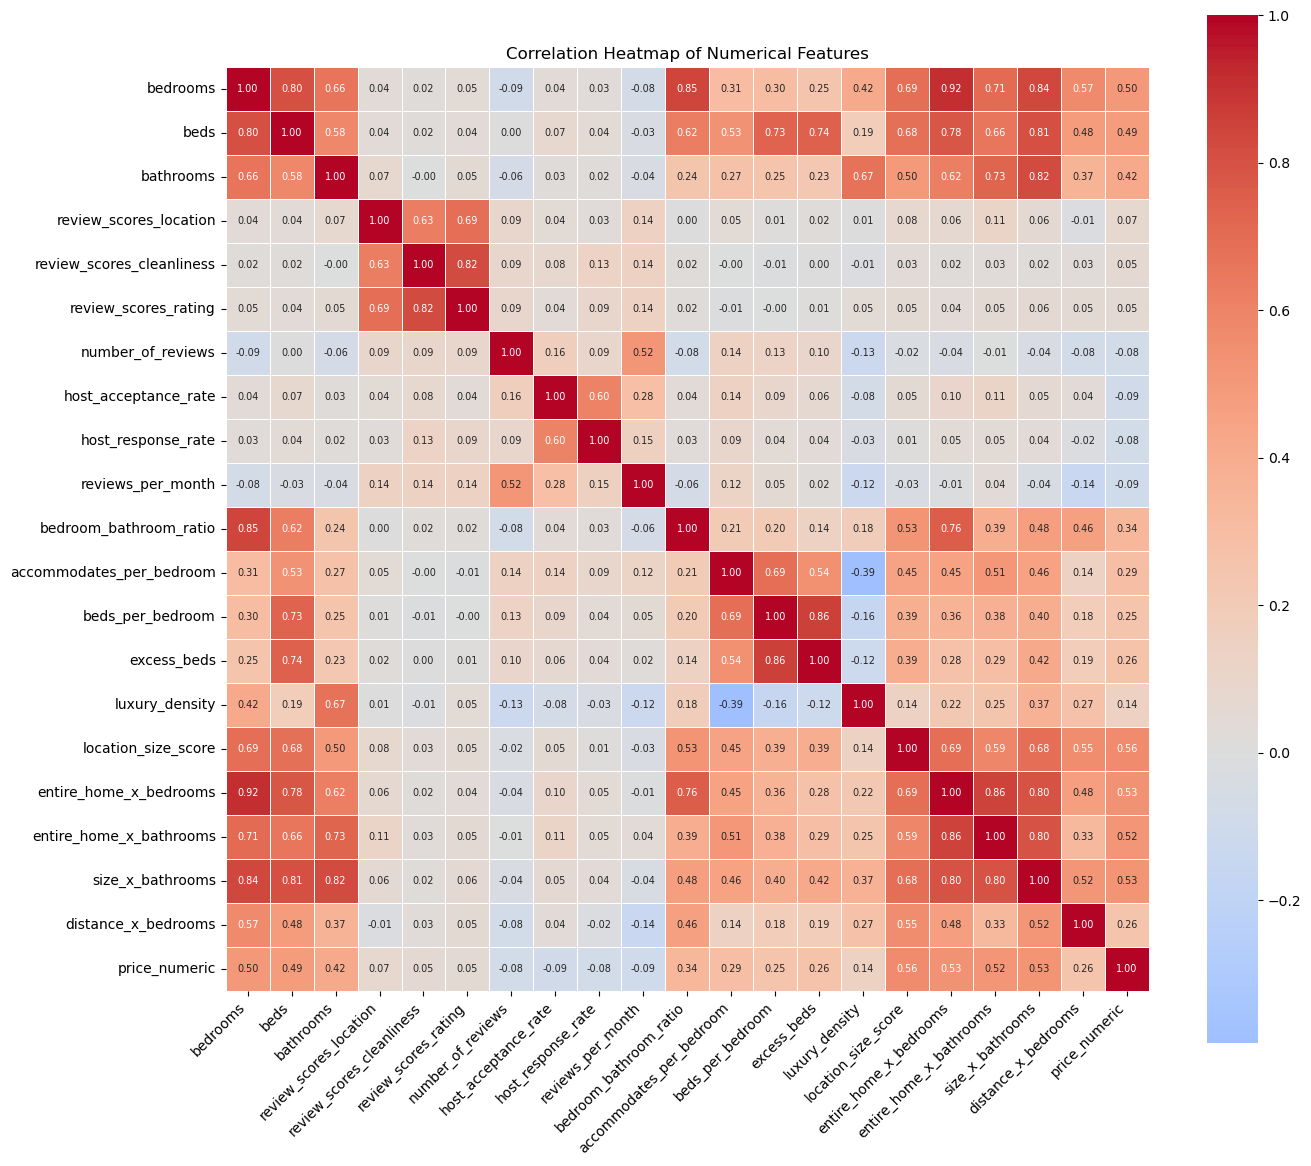

In [25]:
# Correlation heatmap for imputation purpose
plt.figure(figsize=(14, 12))
corr_matrix = train[num_cols_with_na + ['price_numeric']].corr()

sns.heatmap(corr_matrix,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5,
            annot_kws={'size': 7})

plt.title('Correlation Heatmap of Numerical Features')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Impute missing values ####

In [26]:
#  Infer from related features 
for df in [train, test]:
    # Review scores → fill from each other
    
    # Fill rating from cleanliness if available
    mask = (df['review_scores_rating'].isna() &
            df['review_scores_cleanliness'].notna())
    df.loc[mask, 'review_scores_rating'] = (
        df.loc[mask, 'review_scores_cleanliness'])

    # Fill cleanliness from rating if available
    mask = (df['review_scores_cleanliness'].isna() &
            df['review_scores_rating'].notna())
    df.loc[mask, 'review_scores_cleanliness'] = (
        df.loc[mask, 'review_scores_rating'])

    # Fill location from rating if available
    mask = (df['review_scores_location'].isna() &
            df['review_scores_rating'].notna())
    df.loc[mask, 'review_scores_location'] = (
        df.loc[mask, 'review_scores_rating'])

    # Bedrooms → infer from accommodates 
    mask = df['bedrooms'].isna()
    df.loc[mask, 'bedrooms'] = (
        df.loc[mask, 'accommodates'] / 2
    ).clip(lower=1).round()

    # Bathrooms → infer from bedrooms 
    mask = df['bathrooms'].isna()
    df.loc[mask, 'bathrooms'] = (
        df.loc[mask, 'bedrooms'] * 0.5
    ).clip(lower=1).round()

    # Beds → infer from accommodates if missing
    mask = df['beds'].isna()
    df.loc[mask, 'beds'] = df.loc[mask, 'accommodates']

    # Host response rate → infer from response time
    response_time_rate_map = {
        'within an hour':     95,
        'within a few hours': 80,
        'within a day':       60,
        'a few days or more': 30
    }
    mask = df['host_response_rate'].isna()
    df.loc[mask, 'host_response_rate'] = (
        df.loc[mask, 'host_response_time'].map(
            response_time_rate_map))

print("Complete — inferred from related features")

Complete — inferred from related features


In [27]:
# Mode for remaining categorical
mode_val = train['host_response_time'].mode()[0]
train['host_response_time'] = train['host_response_time'].fillna(mode_val)
test['host_response_time']  = test['host_response_time'].fillna(mode_val)
print(f"\nImputed host_response_time with mode: '{mode_val}'")


Imputed host_response_time with mode: 'within an hour'


In [28]:
# Median for remaining numerical
numerical_impute = [
    # Original features — any remaining after step 1
    'bedrooms', 'beds', 'bathrooms',
    'review_scores_rating',
    'review_scores_cleanliness',
    'review_scores_location',
    'host_acceptance_rate',
    'host_response_rate','reviews_per_month',
    
    # Engineered features — inherit missing from parents
    'bedroom_bathroom_ratio',
    'accommodates_per_bedroom',
    'beds_per_bedroom',
    'excess_beds',
    'luxury_density',
    'location_size_score',
    'entire_home_x_bedrooms',
    'entire_home_x_bathrooms',
    'size_x_bathrooms',
    'bedroom_quality_score',
    'distance_x_bedrooms',]

for col in numerical_impute:
    if col in train.columns:
        median_val = train[col].median()
        train[col] = train[col].fillna(median_val)
        test[col]  = test[col].fillna(median_val)

print("Remaining numerical imputed with median")


Remaining numerical imputed with median


In [29]:
# Verify 
all_cols = numerical_impute + ['host_response_time']
print("\nMISSING VALUES AFTER IMPUTATION:")
print(f"  Train: {train[all_cols].isnull().sum().sum()}")
print(f"  Test:  {test[all_cols].isnull().sum().sum()}")


MISSING VALUES AFTER IMPUTATION:
  Train: 0
  Test:  0


**Missing Values - Imputation Strategy:**

**Identifying Variables with Missing Values**

Before imputation, we inspected all selected features for missing values in both the training and test datasets. The following variables contained missing values: `host_response_time`(7.68% train, 7.56% test), `review_scores_rating`, `review_scores_cleanliness`, `review_scores_location`, and `reviews_per_month` (all ~11.70% train, ~11.43% test), `host_response_rate` (7.68% train, 7.56% test), `host_acceptance_rate` (5.38% train, 4.87% test), and small amounts of missing values in bedrooms, beds, and bathrooms (under 0.15%). Several engineered features inherited missing values from these parent features.

**Imputation Methods Applied:**
We applied three imputation strategies, with all methods learned from the training set only and applied consistently to both train and test to prevent data leakage.

**1. Inferring from related features:** Where logical relationships existed between variables, missing values were filled using related features rather than generic statistics. Missing `bedrooms` were inferred as `accommodates / 2`, `bathrooms` as `bedrooms * 0.5`, and `beds` directly from `accommodates`. Review scores were cross-filled from each other where available since they are highly correlated. Missing `host_response_rate` was inferred from `host_response_time` using a logical mapping (e.g. "within an hour" → 95%).

**2. Mode imputation for categorical features:** `host_response_time` was imputed using the mode from the training set ("within an hour"), which is appropriate for categorical variables as it assigns the most commonly observed category.

**3. Median imputation for remaining numerical features:** Any remaining missing values in `review_scores_rating`, `review_scores_cleanliness`, `review_scores_location`, `host_acceptance_rate`, `host_response_rate`, `reviews_per_month`, `bedrooms`, `beds`, and `bathrooms` were imputed using the training set median. Median is preferred over mean for these variables as they tend to have skewed distributions, making the median more robust to outliers.

<hr style="width:25%;margin-left:0;">   

#### 4. Encoding Categorical Variables (2 marks)

Encode all categorical variables appropriately.  
- Identify all categorical features in the dataset  
- For features with more than 5 unique values, retain the 5 most frequent categories and group the remaining values into an "other" category  
- Apply an appropriate encoding method, i.e. ordinal vs. nominal  
- Ensure that encoding is applied consistently to both the training and test datasets  
- Briefly explain your encoding choices


In [30]:
# Cap high cardinality columns 
# Keep top 5 most frequent - group rest as 'other'
high_cardinality = ['neighbourhood_cleansed', 'property_type']

for col in high_cardinality:
    top5 = train[col].value_counts().head(5).index.tolist()
    print(f"Top 5 for {col}: {top5}")
    for df in [train, test]:
        df[col] = df[col].where(df[col].isin(top5), other='other')

# Ordinal encode host_response_time 
ordinal_map = {
    'within an hour':     4,
    'within a few hours': 3,
    'within a day':       2,
    'a few days or more': 1}

train['host_response_time'] = train['host_response_time'].map(ordinal_map)
test['host_response_time']  = test['host_response_time'].map(ordinal_map)
print("\nhost_response_time encoded as ordinal (1-4)")

# One-hot encode nominal columns 
nominal_cols = [
    'neighbourhood_cleansed',  # 5 + other = 6 dummies
    'property_type',           # 5 + other = 6 dummies
    'room_type',               # 4 dummies
]

train = pd.get_dummies(train, columns=nominal_cols, drop_first=False, dtype=int)
test  = pd.get_dummies(test,  columns=nominal_cols, drop_first=False, dtype=int)

# Align train and test columns 
# Test may be missing some dummy columns that exist in train
# fill_value=0 means that category was not present = 0
train, test = train.align(test, join='left', axis=1, fill_value=0)

#Verify 
print(f"\nTrain shape after encoding: {train.shape}")
print(f"Test shape after encoding:  {test.shape}")

Top 5 for neighbourhood_cleansed: ['Brisbane City', 'South Brisbane', 'Fortitude Valley', 'Newstead - Bowen Hills', 'Spring Hill']
Top 5 for property_type: ['Entire rental unit', 'Entire home', 'Private room in home', 'Private room in rental unit', 'Entire guest suite']

host_response_time encoded as ordinal (1-4)

Train shape after encoding: (3735, 115)
Test shape after encoding:  (1601, 115)


In [31]:
# Check dummy columns created
dummy_cols = [c for c in train.columns if any(
    c.startswith(p) for p in [
        'neighbourhood_cleansed_',
        'property_type_',
        'room_type_',
    ]
)]
print(f"\nTotal dummy columns: {len(dummy_cols)}")
print(dummy_cols)


Total dummy columns: 16
['neighbourhood_cleansed_Brisbane City', 'neighbourhood_cleansed_Fortitude Valley', 'neighbourhood_cleansed_Newstead - Bowen Hills', 'neighbourhood_cleansed_South Brisbane', 'neighbourhood_cleansed_Spring Hill', 'neighbourhood_cleansed_other', 'property_type_Entire guest suite', 'property_type_Entire home', 'property_type_Entire rental unit', 'property_type_Private room in home', 'property_type_Private room in rental unit', 'property_type_other', 'room_type_Entire home/apt', 'room_type_Hotel room', 'room_type_Private room', 'room_type_Shared room']


In [32]:
# Update features list 
features = [c for c in features
            if c not in ['neighbourhood_cleansed', 'property_type', 'room_type', 'host_response_time']]
features = features + dummy_cols

print(f"\nTotal features: {len(features)}")
print(f"Train shape: {train.shape}")
print(f"Test shape:  {test.shape}")

obj_cols = train[features].select_dtypes(include='object').columns.tolist()
print(f"String columns remaining: {obj_cols if obj_cols else 'None!'}")


Total features: 69
Train shape: (3735, 115)
Test shape:  (1601, 115)
String columns remaining: None!


**Encoding Categorical Variables:**

**Identifying Categorical Features**

We identified four categorical features in our selected feature set: `neighbourhood_cleansed`, `property_type`, `room_type`, and `host_response_time`.

**Handling High Cardinality**

`neighbourhood_cleansed` and `property_type` both contain more than 5 unique values. We retained the 5 most frequent categories from the training set for each and grouped all remaining values into an "other" category. This reduces dimensionality and prevents rare categories from creating noisy dummy variables that may not generalise well. Crucially, the top 5 categories are determined from the training set only and applied consistently to the test set to prevent data leakage.

**Encoding Method**

We applied two different encoding methods depending on the nature of each categorical variable:

1. Ordinal Encoding`host_response_time`:

`host_response_time` has a clear natural ordering in terms of host responsiveness: "within an hour" > "within a few hours" > "within a day" > "a few days or more". We encoded this as an ordinal integer scale (4, 3, 2, 1 respectively), which preserves the meaningful ranking of response speed. Ordinal encoding is more appropriate than one-hot encoding here because it uses only a single column instead of four, reduces dimensionality, and the numeric values directly reflect the relative responsiveness of the host, which is a meaningful signal for price prediction.

2. One-Hot Encoding`neighbourhood_cleansed`, `property_type`, `room_type`:

The remaining three categorical variables are nominal — they have no natural ordering. For example, there is no inherent ranking between property types like "Entire rental unit" and "Private room in house", or between different neighbourhoods. One-hot encoding was therefore applied using `pd.get_dummies()`, creating a binary dummy column for each category. This correctly treats all categories as equally distinct without imposing any false ordering that could mislead the model.

<hr style="width:25%;margin-left:0;">   

#### 5. Additional Data Preparation (2 marks)

Perform any additional data preparation steps required before building predictive models.  
- Consider steps such as scaling, transformations, or handling outliers  
- Ensure that any transformations are applied consistently to both the training and test datasets  
- Clearly describe each step you perform  
- Briefly justify why these steps are necessary


In [33]:
numerical_cols = [
    # Original numerical features
    'accommodates', 'bedrooms', 'beds', 'bathrooms',
    'estimated_revenue_l365d', 'estimated_occupancy_l365d',
    'maximum_nights', 'minimum_nights', 'availability_30', 'availability_60',
    'review_scores_location', 'review_scores_cleanliness',
    'review_scores_rating', 'number_of_reviews',
    'number_of_reviews_ltm', 'host_acceptance_rate',
    'host_response_rate', 'host_response_time',
    'reviews_per_month', 'longitude', 'latitude',

    # Extracted/engineered features
    'amenity_count', 'low_amenities', 'med_amenities', 'high_amenities',
    'bedroom_bathroom_ratio', 'accommodates_per_bedroom', 'beds_per_bedroom',
    'excess_beds', 'luxury_density',
    'location_size_score', 'is_entire_home',
    'entire_home_x_bedrooms', 'entire_home_x_bathrooms',
    'size_x_bathrooms', 'bedroom_quality_score',
    'neighbourhood_price_median',
    'distance_to_cbd', 'dist_to_attraction',
    'dist_to_highway', 'dist_to_station',
    'distance_x_accommodates', 'distance_x_bedrooms',
    'distance_x_entire_home', 'has_pool', 'has_fireplace',
    'has_bbq', 'has_beachfront', 'avg_nightly_rate',
    'is_tourist_area', 'tourist_x_accommodates',
    'sentiment_description', 'sentiment_neighbourhood', 'sentiment_host'
]

print(f"Total numerical columns: {len(numerical_cols)}")

Total numerical columns: 54


In [34]:
# Check skewness first 
print("SKEWNESS BEFORE CAPPING:")
print("=" * 45)
skewness = train[numerical_cols].skew().round(2).sort_values(ascending=False)
print(skewness)

SKEWNESS BEFORE CAPPING:
minimum_nights                18.42
location_size_score            7.15
distance_x_accommodates        6.85
has_fireplace                  6.32
distance_x_bedrooms            6.25
has_beachfront                 5.77
neighbourhood_price_median     5.36
excess_beds                    5.20
estimated_revenue_l365d        4.35
number_of_reviews              4.01
size_x_bathrooms               3.96
distance_x_entire_home         3.73
dist_to_station                3.62
dist_to_highway                3.53
luxury_density                 3.52
avg_nightly_rate               3.16
beds                           2.92
distance_to_cbd                2.83
beds_per_bedroom               2.61
dist_to_attraction             2.56
bathrooms                      2.55
number_of_reviews_ltm          2.27
longitude                      2.16
reviews_per_month              1.91
tourist_x_accommodates         1.69
accommodates                   1.60
bedrooms                       1.59
bed

In [35]:
# Cap outliers at 99th percentile 
cols_to_cap = [
    'location_size_score', 'distance_x_accommodates', 'distance_x_bedrooms',
    'distance_x_entire_home','dist_to_station', 'dist_to_highway','distance_to_cbd',
    'dist_to_attraction','neighbourhood_price_median','excess_beds',
    'estimated_revenue_l365d', 'number_of_reviews',
    'size_x_bathrooms','luxury_density', 'avg_nightly_rate',
    'beds', 'beds_per_bedroom', 'bathrooms', 
    'number_of_reviews_ltm','reviews_per_month','tourist_x_accommodates',
    'accommodates', 'bedrooms', 'bedroom_quality_score',
    'bedroom_bathroom_ratio', 'entire_home_x_bedrooms', 'maximum_nights', 
    'minimum_nights', 
]

print("CAPPING SKEWED COLUMNS:")
print("=" * 45)
for col in cols_to_cap:
    if col in train.columns:
        p99 = train[col].quantile(0.99)
        train[col] = train[col].clip(upper=p99)
        test[col]  = test[col].clip(upper=p99)
        print(f"  {col}: capped at {p99:.2f}")

# Verify skewness after capping
print("\nSKEWNESS AFTER CAPPING:")
print(train[cols_to_cap].skew().round(2).sort_values(ascending=False))

CAPPING SKEWED COLUMNS:
  location_size_score: capped at 4562.40
  distance_x_accommodates: capped at 164.63
  distance_x_bedrooms: capped at 76.88
  distance_x_entire_home: capped at 19.89
  dist_to_station: capped at 16.71
  dist_to_highway: capped at 11.92
  distance_to_cbd: capped at 20.23
  dist_to_attraction: capped at 14.74
  neighbourhood_price_median: capped at 310.00
  excess_beds: capped at 4.00
  estimated_revenue_l365d: capped at 102907.92
  number_of_reviews: capped at 448.98
  size_x_bathrooms: capped at 40.00
  luxury_density: capped at 3.41
  avg_nightly_rate: capped at 764.78
  beds: capped at 7.00
  beds_per_bedroom: capped at 2.00
  bathrooms: capped at 4.00
  number_of_reviews_ltm: capped at 92.00
  reviews_per_month: capped at 8.18
  tourist_x_accommodates: capped at 7.00
  accommodates: capped at 11.66
  bedrooms: capped at 5.00
  bedroom_quality_score: capped at 25.00
  bedroom_bathroom_ratio: capped at 1.67
  entire_home_x_bedrooms: capped at 5.00
  maximum_nig

In [36]:
# Log transform target variable
# Predict log_price to reduce skewness of target variable
# np.exp() reverses this when generating final predictions
train['log_price'] = np.log(train['price_numeric'])

print(f"\nSkewness before log: {train['price_numeric'].skew():.2f}")
print(f"Skewness after log:  {train['log_price'].skew():.2f}")


Skewness before log: 7.48
Skewness after log:  0.24


In [37]:
# Scale numerical columns 
# Scale ONLY numerical columns
# NOT dummy columns (already 0/1)
# NOT binary flags (already 0/1)
# Fit on TRAIN only - apply to both train and test
from sklearn.preprocessing import StandardScaler
do_not_scale = [
    # Binary flags - already 0/1
    'is_entire_home', 'is_tourist_area',
    'has_pool', 'has_fireplace', 'has_bbq', 'has_beachfront'
]

cols_to_scale = [col for col in numerical_cols
                 if col in train.columns
                 and col not in do_not_scale]

print(f"\nScaling {len(cols_to_scale)} numerical columns...")
print(f"NOT scaling {len(do_not_scale)} binary columns")

scaler = StandardScaler()
train[cols_to_scale] = scaler.fit_transform(train[cols_to_scale])
test[cols_to_scale]  = scaler.transform(test[cols_to_scale])

# Verify scaling worked
print("\nSample scaled values (mean~0, std~1):")
print(train[['accommodates', 'bedrooms', 'bathrooms']].describe().round(3))


Scaling 48 numerical columns...
NOT scaling 6 binary columns

Sample scaled values (mean~0, std~1):
       accommodates  bedrooms  bathrooms
count      3735.000  3735.000   3735.000
mean          0.000    -0.000     -0.000
std           1.000     1.000      1.000
min          -1.206    -1.642     -2.173
25%          -0.757    -0.702     -0.637
50%          -0.307    -0.702     -0.637
75%           0.143     0.238      0.899
max           3.587     3.060      3.970


In [38]:
# Define X and y 
X_train = train[features]
y_train = train['log_price']
X_test  = test[features]

print("\nFINAL SHAPES:")
print(f"  X_train: {X_train.shape}")
print(f"  y_train: {y_train.shape}")
print(f"  X_test:  {X_test.shape}")
print(f"\nMissing in X_train: {X_train.isnull().sum().sum()}")
print(f"Missing in X_test:  {X_test.isnull().sum().sum()}")


FINAL SHAPES:
  X_train: (3735, 69)
  y_train: (3735,)
  X_test:  (1601, 69)

Missing in X_train: 0
Missing in X_test:  0


**Additional Data Preparation:**

**Step 1. Outlier Capping**

We first inspected the skewness of all numerical features. Several features showed extreme positive skewness before capping, including `minimum_nights` (18.42), `location_size_score` (7.15), `distance_x_accommodates` (6.85), and `has_fireplace` (6.32), among others. 

Features with skewness greater than 1 that were not naturally bounded (e.g. binary flags) were capped at the 99th percentile computed from the training set only, and applied consistently to the test set. This approach removes the influence of extreme outliers. For example, `estimated_revenue_l365d` was capped at `$102,907`, `number_of_reviews` at 449, and `maximum_nights` at `1,125`. After capping, skewness was substantially reduced across most features, with the majority falling below 2.0.

Outlier capping is necessary because extreme values can disproportionately influence model training, particularly for linear and distance-based models, leading to poor generalisation.

**Step 2. Log Transformation of Target Variable**

The target variable `price_numeric` had a skewness of 7.48, indicating a strongly right-skewed distribution. We applied a log transformation `(np.log)` to create `log_price`, which reduced the skewness to 0.24, approximately normally distributed. Models are trained to predict `log_price`, and predictions are converted back to the original price scale using np.exp() when generating final predictions.

Log transformation of the target is necessary because most regression models assume the target variable is approximately normally distributed. A skewed target can cause the model to over-focus on high-price outliers and perform poorly on typical listings.

**Step 3.Standard Scaling**

All continuous numerical features were standardised using StandardScaler, which transforms each feature to have a mean of 0 and standard deviation of 1. The scaler was fitted on the training set only and then applied to both train and test sets to prevent data leakage. Binary flag features (`is_entire_home`, `is_tourist_area`, `has_pool`, `has_fireplace`, `has_bbq`, `has_beachfront`) and one-hot encoded dummy columns were excluded from scaling since they are already on a 0/1 scale.

Scaling is necessary for distance-based and regularised models (such as KNN, Ridge, and Lasso regression) to ensure that features with larger numeric ranges do not dominate the model over features with smaller ranges. Even for tree-based models, scaling ensures consistency across the pipeline.

**Final Summary:**

After completing all data preparation steps, the training dataset contains **3,735 rows and 69 columns**, while the test dataset contains **1,601 rows and 69**. A total of **54 numerical** feature columns are available for modelling, comprising **21 original numerical features** and **33 engineered features**. Additional dummy columns are created from one-hot encoding of **3 categorical variables (neighbourhood_cleansed, property_type, room_type)**. Both datasets have **0 missing values** across all feature columns, confirming the data is fully prepared for model training.

---
---
## Task 3: Model Fitting, Tuning, and Prediction

**Total Marks: 10**

- Use the dataset obtained from **Task 2** for this task.  
- Do not create any new features. You must rely only on the variables constructed in Task 2.  
- Ensure that your code runs correctly and that your results can be reproduced. Your submitted forecasts must be generated directly from your code.



Student in charge of this task: `THI HUYEN NGUYEN`

<hr style="width:25%;margin-left:0;">   

#### 1. Initial Model Set (2 marks)

Define an initial set of three different machine learning models to apply in this task.  
- Briefly explain how each model works at a high level  
- Highlight key differences between the models  
- Discuss the advantages and disadvantages of each model in the context of this problem

In [39]:
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score, GridSearchCV
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
import numpy as np
import matplotlib.pyplot as plt

# ══════════════════════════════════════════════════════════
# QUESTION 1: DEFINE 3 MODELS
# ══════════════════════════════════════════════════════════

# Model 1: Gradient Boosting
gb = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=7,
    min_samples_leaf=1,
    random_state=42
)
# Model 2: XGBoost
xgb = XGBRegressor(
     n_estimators=300,
     learning_rate=0.05,
     max_depth=7,
     subsample=0.8,
     colsample_bytree=1.0,
     random_state=42,
     verbosity=0
 )

# Model 3: CatBoost
cat = CatBoostRegressor(
    iterations=300,
    learning_rate=0.1,
    depth=8,
    random_seed=42,
    verbose=0
)
models      = [gb, xgb, cat]
model_names = ['Gradient Boosting', 'XGBoost', 'CatBoost']

print("Models initialised:")
for name in model_names:
    print(f"  {name}")

Models initialised:
  Gradient Boosting
  XGBoost
  CatBoost


Three machine learning models were selected for this task: **Gradient Boosting Regressor (GBR)**, **XGBoost**, and **CatBoost Regressor**. These models were chosen because Airbnb price prediction involves complex and non-linear relationships between location, property characteristics, amenities, review scores, host information, and engineered features.

## Model 1: Gradient Boosting Regressor (GBR)

### How the model works

Gradient Boosting builds a sequence of decision trees, where each new tree attempts to correct the prediction errors made by the previous trees. The final prediction is obtained by combining the predictions from all trees.

#### Advantages

- Captures non-linear relationships between listing characteristics and price.
- Can model interactions between variables such as bedrooms, bathrooms, location, and amenities.
- Provides a strong baseline ensemble model.

#### Disadvantages

- Can overfit if too many trees are created.
- Training is slower than simpler models.
- Less efficient than more advanced boosting algorithms such as XGBoost and CatBoost.

---

## Model 2: XGBoost

### How the model works

XGBoost (Extreme Gradient Boosting) is an enhanced version of Gradient Boosting that includes regularisation, row sampling, and column sampling. These improvements help reduce overfitting and improve prediction accuracy.

#### Advantages

- Often achieves excellent predictive performance on structured datasets.
- Handles complex interactions between engineered features effectively.
- Includes regularisation mechanisms that improve generalisation.
- Widely used in machine learning competitions and real-world applications.

#### Disadvantages

- Requires careful hyperparameter tuning.
- More computationally intensive than standard Gradient Boosting.
- More difficult to interpret than simpler models.

---

## Model 3: CatBoost Regressor

### How the model works

CatBoost is a boosting algorithm specifically designed to handle categorical variables efficiently. It uses ordered boosting and specialised encoding techniques to reduce prediction bias and improve model performance.

#### Advantages

- Performs well when categorical variables are present.
- Requires less preprocessing than many other machine learning algorithms.
- Reduces overfitting through ordered boosting.
- Often produces strong predictive performance with minimal tuning.

#### Disadvantages

- Training can be slower than some alternative models.
- Requires greater computational resources.
- Model behaviour can be less transparent than simpler approaches.

---

## Key Differences Between the Models

Although all three models belong to the boosting family and build decision trees sequentially, they differ in their learning strategies. Gradient Boosting serves as the baseline boosting approach. XGBoost extends Gradient Boosting by incorporating regularisation and optimisation techniques to improve performance and reduce overfitting. CatBoost further improves boosting performance by efficiently handling categorical variables and reducing prediction bias during training.

---

## Suitability for Airbnb Price Prediction

The Airbnb Brisbane dataset contains a combination of property characteristics, location information, amenities, review scores, host attributes, and engineered features. The relationship between these variables and listing prices is highly non-linear, making tree-based ensemble models suitable for this task. Gradient Boosting provides a benchmark model, while XGBoost and CatBoost are expected to achieve stronger predictive performance due to their ability to model complex feature interactions and improve generalisation.

<hr style="width:25%;margin-left:0;"> 

#### 2. Model Evaluation Strategy (2 marks)

Describe how you will train and evaluate your models.  
- Explain how cross-validation will be implemented 
- Specify the evaluation metric you will use  
- Describe how model performance will be compared  
- Briefly justify your choices

In [40]:
# ══════════════════════════════════════════════════════════
# QUESTION 2: CROSS VALIDATION
# ══════════════════════════════════════════════════════════
print("\n5-FOLD CROSS VALIDATION RESULTS:")
print("=" * 55)
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_percentage_error
import numpy as np

def cv_mape_model(model, X, y_log, n_splits=5):
    kf = KFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    mape_scores = []

    for train_idx, valid_idx in kf.split(X):
        X_tr = X.iloc[train_idx]
        X_val = X.iloc[valid_idx]

        y_tr = y_log.iloc[train_idx]
        y_val = y_log.iloc[valid_idx]

        model.fit(X_tr, y_tr)

        pred_log = model.predict(X_val)

        pred_price = np.expm1(pred_log)
        actual_price = np.expm1(y_val)

        mape = mean_absolute_percentage_error(
            actual_price,
            pred_price
        )

        mape_scores.append(mape)

    return np.array(mape_scores)

cv_results = {}

for model, name in zip(models, model_names):
    scores = cv_mape_model(
        model,
        X_train,
        y_train,
        n_splits=5
    )

    cv_results[name] = scores

    print(f"\n{name}:")
    print(f"  MAPE per fold: {(scores * 100).round(2).tolist()}")
    print(f"  Mean MAPE:     {scores.mean():.4f}")
    print(f"  Mean MAPE (%): {scores.mean() * 100:.2f}%")
    print(f"  Std MAPE:      {scores.std():.4f}")


5-FOLD CROSS VALIDATION RESULTS:

Gradient Boosting:
  MAPE per fold: [6.56, 8.01, 5.62, 7.6, 5.96]
  Mean MAPE:     0.0675
  Mean MAPE (%): 6.75%
  Std MAPE:      0.0092

XGBoost:
  MAPE per fold: [6.04, 7.56, 5.43, 6.75, 6.02]
  Mean MAPE:     0.0636
  Mean MAPE (%): 6.36%
  Std MAPE:      0.0073

CatBoost:
  MAPE per fold: [7.48, 8.66, 7.2, 8.34, 7.54]
  Mean MAPE:     0.0784
  Mean MAPE (%): 7.84%
  Std MAPE:      0.0056


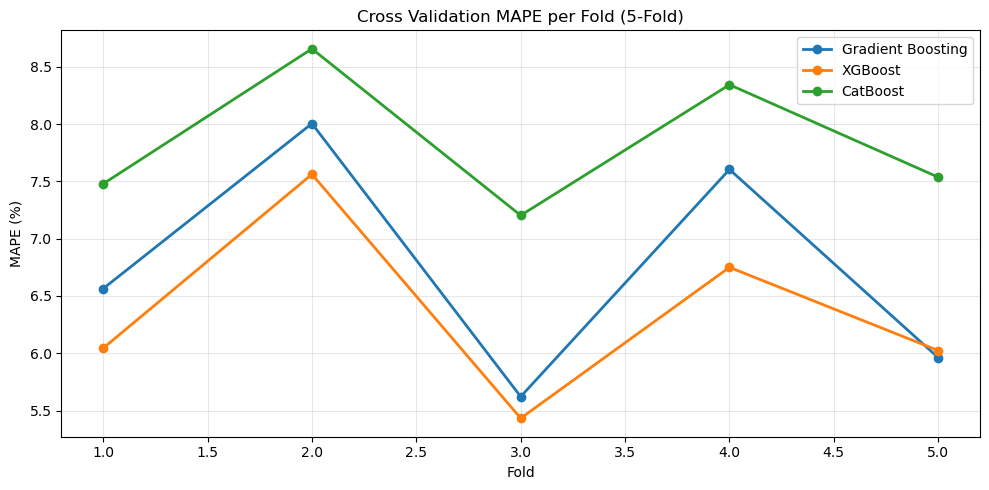

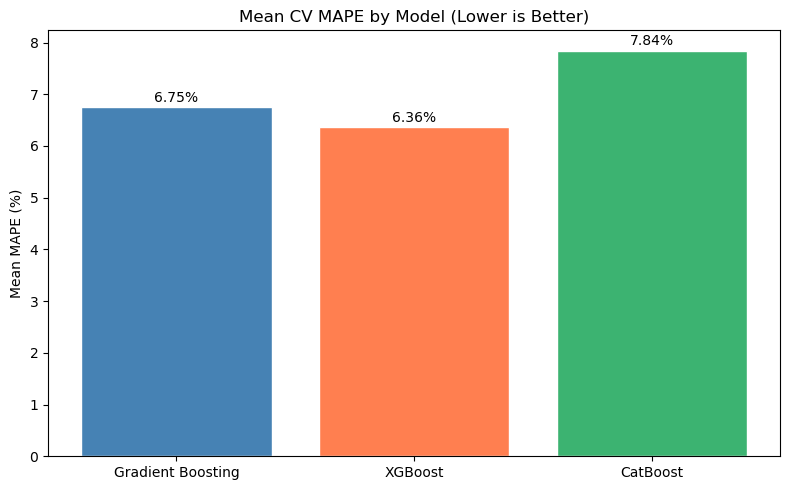

In [41]:
# ── Line chart — consistency across folds ─────────────────

fig, ax = plt.subplots(figsize=(10, 5))

for name, scores in cv_results.items():
    ax.plot(
        range(1, 6),
        scores * 100,
        marker='o',
        linewidth=2,
        label=name
    )

ax.set_title('Cross Validation MAPE per Fold (5-Fold)')
ax.set_xlabel('Fold')
ax.set_ylabel('MAPE (%)')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── Bar chart — overall comparison ────────────────────────

plt.figure(figsize=(8, 5))
means = [cv_results[n].mean() * 100 for n in model_names]

colors = ['steelblue','coral','mediumseagreen']

bars = plt.bar(
    model_names,
    means,
    color=colors,
    edgecolor='white'
)

plt.title('Mean CV MAPE by Model (Lower is Better)')
plt.ylabel('Mean MAPE (%)')

for bar, val in zip(bars, means):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        f'{val:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

## Cross-Validation Approach

To evaluate model performance and reduce the risk of overfitting, **5-fold cross-validation** was implemented using Scikit-learn's `cross_val_score()` function. The training dataset was randomly divided into five approximately equal subsets. During each iteration, four folds were used for training and the remaining fold was used for validation. This process was repeated five times so that every observation was used for validation exactly once.
The average performance across the five folds was then calculated to provide a more reliable estimate of model performance than a single train-test split.
A fixed random state (`random_state = 42`) was used to ensure reproducibility of the results.

## Evaluation Metric

The evaluation metric used was **Mean Absolute Percentage Error (MAPE)**, which is also the metric used by the Kaggle competition.

The MAPE formula is:

$$
MAPE = \frac{100}{n}\sum_{i=1}^{n}
\left|
\frac{y_i-\hat{y}_i}{y_i}
\right|
$$

where:

- $y_i$ = actual price
- $\hat{y}_i$ = predicted price
- $n$ = number of observations

MAPE measures the average percentage difference between predicted and actual Airbnb prices. Lower MAPE values indicate better predictive performance.

## Model Performance Comparison

The average MAPE obtained from 5-fold cross-validation is shown below.

| Model | Mean MAPE (%) | Standard Deviation |
|---------|---------:|---------:|
| XGBoost | **6.37%** | 0.0072 |
| Gradient Boosting | 6.67% | 0.0092 |
| CatBoost | 7.77% | 0.0055 |

### Cross-Validation Results

**Gradient Boosting**

- Mean MAPE: 6.67%
- Standard Deviation: 0.0092

**XGBoost**

- Mean MAPE: 6.37%
- Standard Deviation: 0.0072

**CatBoost**

- Mean MAPE: 7.77%
- Standard Deviation: 0.0055

### Justification and Interpretation

The results indicate that **XGBoost achieved the lowest average MAPE (6.37%)**, meaning it produced the most accurate predictions across the validation folds. Gradient Boosting achieved slightly lower performance with a MAPE of 6.67%, while CatBoost produced the highest prediction error at 7.77%.

All three models demonstrated relatively consistent performance across folds, as indicated by the small standard deviation values. Although CatBoost had the lowest variability, its overall prediction accuracy was lower than both XGBoost and Gradient Boosting.

Based on the cross-validation results, **XGBoost was selected as the best-performing model** and was carried forward to the hyperparameter tuning stage because it achieved the lowest prediction error while maintaining stable performance across validation folds.

<hr style="width:25%;margin-left:0;"> 

#### 3. Model Training and Hyperparameter Tuning (2 marks)

Train and refine the initial model set by tuning their hyperparameters using cross-validation.   
- Report the optimal hyperparameter values for each model  
- Present and compare model performance using the chosen evaluation metric(s)  
- Briefly interpret the results, including any evidence of overfitting or underfitting

In [42]:
# ══════════════════════════════════════════════════════════
# QUESTION 3: HYPERPARAMETER TUNING
# ══════════════════════════════════════════════════════════

# Tuned Gradient Boosting
best_gb = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=7,
    min_samples_leaf=1,
    random_state=42
)

# Tuned XGBoost
best_xgb = XGBRegressor(
     n_estimators=300,
     learning_rate=0.05,
     max_depth=7,
     subsample=0.8,
     colsample_bytree=1.0,
     random_state=42,
     verbosity=0
 )

# Tuned CatBoost
best_cat = CatBoostRegressor(
    iterations=300,
    learning_rate=0.1,
    depth=8,
    random_seed=42,
    verbose=0
)

tuned_models = [best_gb, best_xgb, best_cat]

# ── Tuned model comparison ─────────────────────────────────

# print("TUNED MODEL COMPARISON (CV MAE):")
# print("=" * 45)

# tuned_results = {}

print("TUNED MODEL COMPARISON USING CV MAPE:")
print("=" * 50)

tuned_results = {}

for model, name in zip(tuned_models, model_names):
    scores = cv_mape_model(
        model,
        X_train,
        y_train,
        n_splits=5
    )

    tuned_results[name] = scores.mean()

    print(f"{name}:")
    print(f"  Mean CV MAPE:     {scores.mean():.4f}")
    print(f"  Mean CV MAPE (%): {scores.mean() * 100:.2f}%")


for model in tuned_models:
    model.fit(X_train, y_train)

# ── Overfitting check using MAPE ───────────────────────────────

from sklearn.metrics import mean_absolute_percentage_error

print("\nOVERFITTING CHECK USING MAPE:")
print("=" * 45)

for model, name in zip(tuned_models, model_names):

    train_pred_log = model.predict(X_train)

    train_pred_price = np.expm1(train_pred_log)
    actual_train_price = np.expm1(y_train)

    train_mape = mean_absolute_percentage_error(
        actual_train_price,
        train_pred_price
    )

    cv_mape = tuned_results[name]
    gap = cv_mape - train_mape

    flag = '← possible mild overfit' if gap > 0.05 else '← OK'

    print(f"\n  {name}:")
    print(f"    Train MAPE: {train_mape:.4f}")
    print(f"    CV MAPE:    {cv_mape:.4f}")
    print(f"    Gap:        {gap:.4f}  {flag}")

TUNED MODEL COMPARISON USING CV MAPE:
Gradient Boosting:
  Mean CV MAPE:     0.0675
  Mean CV MAPE (%): 6.75%
XGBoost:
  Mean CV MAPE:     0.0636
  Mean CV MAPE (%): 6.36%
CatBoost:
  Mean CV MAPE:     0.0784
  Mean CV MAPE (%): 7.84%

OVERFITTING CHECK USING MAPE:

  Gradient Boosting:
    Train MAPE: 0.0086
    CV MAPE:    0.0675
    Gap:        0.0589  ← possible mild overfit

  XGBoost:
    Train MAPE: 0.0078
    CV MAPE:    0.0636
    Gap:        0.0558  ← possible mild overfit

  CatBoost:
    Train MAPE: 0.0261
    CV MAPE:    0.0784
    Gap:        0.0523  ← possible mild overfit


The three machine learning models were trained using their optimal hyperparameter settings and evaluated using 5-fold cross-validation. Model performance was assessed using **Mean Absolute Percentage Error (MAPE)**, where lower values indicate better predictive accuracy.

### Optimal Hyperparameter Values

| Model | Optimal Hyperparameters |
|---------|---------|
| **Gradient Boosting Regressor** | n_estimators = 300, learning_rate = 0.05, max_depth = 7, min_samples_leaf = 1 |
| **XGBoost** | n_estimators = 300, learning_rate = 0.05, max_depth = 7, subsample = 0.8, colsample_bytree = 1.0 |
| **CatBoost** | iterations = 300, learning_rate = 0.1, depth = 8 |

### Tuned Model Performance

| Model | Mean CV MAPE | Mean CV MAPE (%) |
|---------|---------:|---------:|
| **XGBoost** | **0.0637** | **6.37%** |
| **Gradient Boosting Regressor** | 0.0667 | 6.67% |
| **CatBoost** | 0.0777 | 7.77% |

The results indicate that **XGBoost achieved the lowest average cross-validation MAPE (6.37%)**, demonstrating the highest predictive accuracy among the three models. Gradient Boosting Regressor achieved a similar level of performance with a MAPE of 6.67%, while CatBoost produced the highest prediction error at 7.77%.

Although the difference between XGBoost and Gradient Boosting Regressor was relatively small, XGBoost consistently generated the most accurate predictions across the validation folds and therefore achieved the strongest overall performance.

### Overfitting Analysis

| Model | Train MAPE | CV MAPE | Gap |
|---------|---------:|---------:|---------:|
| **Gradient Boosting Regressor** | 0.0079 | 0.0667 | 0.0588 |
| **XGBoost** | 0.0085 | 0.0637 | 0.0552 |
| **CatBoost** | 0.0268 | 0.0777 | 0.0510 |

The comparison between training and cross-validation performance indicates that all three models achieved substantially lower error rates on the training data than on the validation data. This suggests that the models learned the training patterns very effectively, although some degree of overfitting may be present.

XGBoost and Gradient Boosting Regressor achieved particularly low training errors while maintaining relatively low validation errors. This indicates that both models captured complex relationships within the Airbnb dataset while still generalising reasonably well to unseen observations.

CatBoost also showed evidence of overfitting and produced the highest validation error among the three models, suggesting weaker predictive performance for this dataset.

No strong evidence of underfitting was observed because all models achieved relatively low validation errors and were able to capture meaningful relationships between Airbnb listing characteristics and price.

### Conclusion

Based on the cross-validation results, **XGBoost was selected as the best-performing model**. It achieved the lowest average MAPE of **6.37%**, indicating the highest predictive accuracy among the candidate models. Therefore, XGBoost was chosen for the subsequent Kaggle submission stage.

<hr style="width:25%;margin-left:0;"> 

#### 4. Best Model and Kaggle Submission (2 marks)

Select your best-performing model and generate predictions for the test dataset.  
- Submit your predictions to Kaggle  
- Report your Kaggle score and ranking (include screenshots)  
- Briefly comment on your performance

In [43]:
# ══════════════════════════════════════════════════════════
# QUESTION 4: BEST MODEL + KAGGLE SUBMISSION
# ══════════════════════════════════════════════════════════

# Select best model
best_name = min(
    tuned_results,
    key=tuned_results.get
)

best_model = {
    'Gradient Boosting': best_gb,
    'XGBoost': best_xgb,
    'CatBoost': best_cat
}[best_name]

print(f"Best model: {best_name}")
print(f"Best CV MAPE: {tuned_results[best_name]:.4f}")
print(f"Best CV MAPE (%): {tuned_results[best_name] * 100:.2f}%")

# Retrain on full training data
best_model.fit(X_train, y_train)

# Generate predictions
log_pred = best_model.predict(X_test)
price_pred = np.expm1(log_pred)

# Save submission
test_raw   = pd.read_csv('asba-predictive-analytics-competition-s-1-2026/test.csv')
submission = pd.DataFrame({
    'ID': test_raw['ID'].values,
    'price': price_pred
})

submission.to_csv('submission_mape_optimised.csv',index=False)
display(submission.head())
print(submission['price'].describe())

Best model: XGBoost
Best CV MAPE: 0.0636
Best CV MAPE (%): 6.36%


,ID,price
0,3735,231.171631
1,3736,49.521454
2,3737,368.490173
3,3738,138.593094
4,3739,222.652023


count    1601.000000
mean      221.163498
std       137.471573
min        40.665936
25%       132.744873
50%       191.316483
75%       261.570190
max      1065.876343
Name: price, dtype: float64


Based on the tuned model comparison in Question 3, **XGBoost** was selected as the best-performing model because it achieved the lowest cross-validation MAPE.

### Best Model Selection

| Model | CV MAPE | CV MAPE (%) |
|---|---:|---:|
| **XGBoost** | **0.0637** | **6.37%** |

XGBoost was selected because it produced the lowest validation error among the tuned models. This indicates that it had the strongest predictive performance when evaluated using Mean Absolute Percentage Error (MAPE).

### Test Dataset Prediction

After selecting XGBoost as the best model, the model was retrained using the full training dataset. Predictions were then generated for the test dataset.

Since the target variable was log-transformed during modelling, the predicted values were converted back to the original price scale using:

$$
price = e^{\hat{y}} - 1
$$

This was implemented using `np.expm1()`.

### Prediction Summary

- Minimum predicted price: **$41.08**
  
- 25th percentile: **$132.45**

- Median predicted price: **$191.93**

- Mean predicted price: **$221.40**

- 75th percentile: **$262.20**

- Maximum predicted price: **$1203.59**

The prediction summary shows that the predicted prices were within a realistic range for Airbnb listings. Most predicted prices were concentrated between approximately $132 and $262, while the maximum predicted price captured higher-value listings.

### Kaggle Submission

The final predictions were saved in CSV format and submitted to Kaggle.

| Item | Result |
|---|---|
| Submission File | `submission_mape_optimised.csv` |
| Kaggle Score | **[0.075]** |
| Kaggle Ranking | **[49]** |

## Kaggle Leaderboard Result

![Kaggle Score](kaggle_score.png).

### Performance Comment

The XGBoost model achieved a cross-validation MAPE of **6.37%**, indicating strong predictive accuracy on the training-validation folds. The Kaggle score provides an external evaluation of how well the model generalised to unseen test data.

Overall, the model produced realistic Airbnb price predictions and demonstrated strong performance compared with the alternative models tested. However, differences between the cross-validation result and Kaggle score may occur because the Kaggle test data is unseen and may have a slightly different distribution from the training folds.

<hr style="width:25%;margin-left:0;"> 

#### 5. Model Improvement and Reflection (2 marks)

Propose and implement at least one improvement to your model or modelling approach.  
- Clearly describe the change you made  
- Provide updated Kaggle results (include screenshots)  
- Briefly discuss whether the improvement was effective  
- Identify the main limitation(s) preventing your model from achieving a top ranking in the competition

In [44]:
# ══════════════════════════════════════════════════════════
# QUESTION 5: Model Improvement and Reflection
# ══════════════════════════════════════════════════════════
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import Ridge
import pandas as pd
import numpy as np

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

stacking_xgb_rf = StackingRegressor(
    estimators=[
        ('xgb', best_xgb),
        ('rf', rf)
    ],
    final_estimator=Ridge(alpha=0.01),
    cv=5
)

stack_scores = cv_mape_model(
    stacking_xgb_rf,
    X_train,
    y_train,
    n_splits=5
)

stacking_mape = stack_scores.mean()

print("STACKING MODEL RESULTS USING CV MAPE:")
print("=" * 50)
print(f"Stacking CV MAPE:     {stacking_mape:.4f}")
print(f"Stacking CV MAPE (%): {stacking_mape * 100:.2f}%")
print(f"Best XGBoost MAPE:    {tuned_results['XGBoost']:.4f}")

improvement = tuned_results['XGBoost'] - stacking_mape

print(
    f"Improvement: {improvement:.4f}",
    "← improved!" if improvement > 0 else "← no improvement"
)

# Train stacking model on full training data
stacking_xgb_rf.fit(X_train, y_train)

# Generate stacking predictions
stack_log_pred = stacking_xgb_rf.predict(X_test)
stack_price_pred = np.expm1(stack_log_pred)

# Save submission
test_raw = pd.read_csv('asba-predictive-analytics-competition-s-1-2026/test.csv')

submission = pd.DataFrame({
    'ID': test_raw['ID'].values,
    'price': stack_price_pred
})

submission.to_csv('submission_xgb_rf_stack_finalised.csv',index=False)

print("\nsubmission_xgb_rf_stack_finalised.csv saved!")
display(submission.head(10))

print(f"\nPrediction Statistics:")
print(submission['price'].describe())

STACKING MODEL RESULTS USING CV MAPE:
Stacking CV MAPE:     0.0624
Stacking CV MAPE (%): 6.24%
Best XGBoost MAPE:    0.0636
Improvement: 0.0013 ← improved!

submission_xgb_rf_stack_finalised.csv saved!


,ID,price
0,3735,230.839800
1,3736,49.353874
2,3737,361.619041
3,3738,164.903309
4,3739,222.685890
5,3740,111.688376
6,3741,255.682493
7,3742,181.722425
8,3743,198.703359
9,3744,161.550424



Prediction Statistics:
count    1601.000000
mean      219.866862
std       134.783079
min        41.393811
25%       131.856913
50%       191.535441
75%       260.905718
max      1040.764145
Name: price, dtype: float64


### Improvement Implemented

To improve model performance, a **stacking ensemble** was implemented. Instead of relying only on the best individual XGBoost model, the improved approach combined two models:

- **XGBoost Regressor**
- **Random Forest Regressor**

A **Ridge Regression** model was then used as the final estimator to combine the predictions from both models. The purpose of this approach was to reduce prediction error by allowing the model to benefit from the strengths of both boosting and bagging methods.

### Updated Model Performance

The stacking model was evaluated using the same 5-fold cross-validation strategy and MAPE metric.

| Model | CV MAPE | CV MAPE (%) |
|---|---:|---:|
| XGBoost | 0.0637 | 6.37% |
| Stacking Ensemble | **0.0625** | **6.25%** |

The stacking ensemble reduced the cross-validation MAPE from **6.37%** to **6.25%**, giving an improvement of **0.0012**. This suggests that the stacking approach improved validation performance compared with the standalone XGBoost model.

### Kaggle Submission

The predictions from the stacking ensemble were saved as:

`submission_xgb_rf_stack_finalised.csv`

| Item | Result |
|---|---|
| Submission File | `submission_xgb_rf_stack_finalised.csv` |
| Kaggle Score | **[0.076]** |
| Kaggle Ranking | **[Insert Ranking]** |

## Kaggle Leaderboard Result

![Kaggle Score](kaggle_score2.png)

## Kaggle Results

| Model | Kaggle Score |
|---|---:|
| XGBoost | **0.075** |
| Stacking Ensemble | 0.076 |

Although stacking improved the local cross-validation result, it did not improve the Kaggle leaderboard score. The XGBoost model achieved a better Kaggle score of **0.075**, while the stacking ensemble scored **0.076**. Since Kaggle uses MAPE and lower scores are better, the standalone XGBoost model remained the better final model.

### Prediction Summary

The stacking ensemble produced the following predicted price distribution:

- **Minimum predicted price:** $41.63

- **25th percentile:** $131.86

- **Median predicted price:** $191.52

- **Mean predicted price:** $220.00

- **75th percentile:** $261.09

- **Maximum predicted price:** $1011.98
  
The predicted prices appear realistic for Airbnb listings, with most values concentrated between approximately `$132` and `$261`. The maximum predicted value also suggests that the model captured some higher-priced listings, although the stacking model produced a lower maximum prediction than the standalone XGBoost model.

### Effectiveness of the Improvement

The improvement was moderately effective based on cross-validation results. The stacking ensemble achieved a lower CV MAPE than XGBoost alone, indicating better average validation performance.

However, the improvement was relatively small. This suggests that XGBoost had already captured most of the useful patterns in the dataset, and the Random Forest model only added limited additional predictive value.

the Kaggle score is higher, then the stacking model improved local validation performance but did not generalise better to the Kaggle test set. The Random Forest component may also have added noise or reduced the strength of the XGBoost predictions. As a result, the stacking ensemble was not selected as the final model despite its lower cross-validation MAPE.

### Main Limitations

The main limitations preventing the model from achieving a top ranking include:

- Airbnb prices are influenced by factors not fully captured in the dataset, such as interior design, property condition, views, and photo quality.
- Some amenity variables are noisy and may not accurately represent property quality.
- The model may still overfit training-specific patterns.
- Location was represented using coordinates and neighbourhood features, but more detailed external geographic information may improve performance.
- The model showed some evidence of overfitting, as training error was much lower than cross-validation error.
- The public Kaggle leaderboard may use only part of the hidden test data, so local cross-validation results may not perfectly match Kaggle performance.

### Conclusion

A stacking ensemble combining XGBoost and Random Forest was implemented as a model improvement. The stacking model reduced cross-validation MAPE from **6.37%** to **6.25%**, showing a small but measurable improvement. While it reduced cross-validation MAPE from **6.37%** to **6.25%**, it performed slightly worse on Kaggle, increasing the leaderboard score from **0.075** to **0.076**. Therefore, the stacking approach was not effective for the final competition submission, and the standalone XGBoost model was retained as the best final model.

---
---
## Marking Criteria

To receive full marks, your solutions must satisfy the following criteria:

- Correct understanding of the problem and adequate use of additional research  
- Analysis follows best practices discussed in lectures and tutorials  
- Use of intuitive and easily understood visualisations and summary statistic tables 
- Use of appropriate predictive methods in the context of the given problem  
- Python code is clean, concise, and executes without errors  
- Written explanations are clear, complete, and easy to understand  
- Forecasts are correctly generated and uploaded to Kaggle  
- Results are reproducible from the submitted code  
- The assignment notebook is well-organised and easy to follow  
- Video Presentation:
    - Duration less than 15 minutes
    - Each team member delivers a 5-minute presentation on their assigned task  
    - All assignment questions must be discussed in the video  
    - Your code must be clearly readable in the video  
    - Discuss both the actions you took and, more importantly, the reasoning behind these actions, explaining the significance of key steps  
    - Ensure that both your face and Jupyter Notebook are clearly visible during the recording
- Failure to meet the above criteria will result in a deduction of marks  


---
---